# Tuần 11 — Khái quát dữ liệu (7/7): Kiểm định hai mẫu, χ² và lực kiểm định

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Phụ gia mới làm sơn khô trong 112 phút thay vì 121 phút. Dây chuyền B có 14,5% sản phẩm lỗi, dây chuyền A chỉ 9%. Nhân viên lương theo giờ chọn gói bảo hiểm 3 nhiều hơn hẳn nhân viên lương cố định.

Trong cả ba trường hợp, hai nhóm **trong mẫu** khác nhau. Khi nào khác biệt ấy là bằng chứng về **tổng thể**? Cần chọn kiểm định nào cho từng loại dữ liệu? Và dù làm đúng mọi bước, ta vẫn có thể kết luận sai theo những cách nào?

### Sau buổi này, bạn làm được

- xác định loại biến kết quả, tham số cần so sánh và thiết kế (độc lập hay ghép cặp) trước khi chọn kiểm định;
- tính kiểm định z, t gộp, t Welch và t ghép cặp cho hai trung bình bằng công thức, rồi đối chiếu với SciPy;
- kiểm định hai tỉ lệ bằng tỉ lệ gộp; nhận diện kiểm định F cho hai phương sai;
- tính kiểm định $\chi^2$ độ phù hợp và $\chi^2$ tính độc lập, kiểm tra điều kiện về tần số kỳ vọng;
- phân biệt giá trị p, mức ý nghĩa $\alpha$, sai lầm loại I, loại II và lực kiểm định.

Nội dung đáp ứng **LLO11.1–11.2/CLO3** của đề cương.

### Cần nhớ từ các buổi trước

- **Sáu bước kiểm định** (Tuần 10). $H_0$ và $H_A$ chọn trước; thống kê; phân phối dưới $H_0$; giá trị p; kết luận có phạm vi.
- **Giá trị p** (Tuần 10). $P_{H_0}$(thống kê ít nhất cực đoan như đã quan sát). Không phải xác suất $H_0$ đúng.
- **Phân phối $t$ và $\chi^2$** (Tuần 07). $t_\nu$ giống chuẩn tắc nhưng đuôi dày hơn; $\chi^2_\nu$ là tổng bình phương của $\nu$ biến chuẩn tắc độc lập, chỉ nhận giá trị dương.
- **Phương sai của hiệu** (Tuần 07). Nếu $X, Y$ độc lập thì $\mathrm{Var}(X-Y)=\mathrm{Var}(X)+\mathrm{Var}(Y)$.
- **Sai số chuẩn** (Tuần 09). $SE(\bar X)=\sigma/\sqrt n$, $SE(\hat p)=\sqrt{p(1-p)/n}$.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Matplotlib/Plotly](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–3: chọn kiểm định, hai trung bình (Ví dụ 1–4), hai tỉ lệ (Ví dụ 5). Mục 5–7: $\chi^2$ và sai lầm (Ví dụ 7–12). |
| Tự luyện | Câu hỏi 1, tự giải tay mọi ví dụ trước khi mở đáp án, đối chiếu với output Python. |
| Đọc sâu | Mục 4 (kiểm định F, tự chọn như slide); các khối **Vì sao?**; mô phỏng lực kiểm định và so sánh bội ở cuối mục 7. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Đơn vị và câu hỏi đi trước công thức](#muc-1) · [2. Hai trung bình: cùng câu hỏi, bốn sai số chuẩn](#muc-2) · [3. Hai tỉ lệ: dùng tỉ lệ chung dưới H₀](#muc-3) · [4. So sánh hai phương sai — tự chọn](#muc-4) · [5. χ² độ phù hợp: xét cả phân phối](#muc-5) · [6. χ² tính độc lập: từ bảng O sang bảng E](#muc-6) · [7. Sai lầm và lực kiểm định là xác suất của quy trình](#muc-7)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| $\mu_1-\mu_2$ | muy một trừ muy hai | hiệu hai trung bình tổng thể (tham số cần kiểm định) | thời gian khô cũ − mới |
| $\Delta_0$ | đen-ta không | hiệu giả định trong $H_0$, thường bằng 0 | $H_0:\mu_1-\mu_2=0$ |
| $s_p^2$ | phương sai gộp | phương sai chung ước lượng từ hai mẫu khi giả định $\sigma_1=\sigma_2$ | $s_p^2\approx7{,}30$ |
| $\nu$, $df$ | nuy, bậc tự do | tham số của phân phối $t$, $F$, $\chi^2$ | $\nu=n_1+n_2-2=14$ |
| $D_i$, $\bar d$, $s_D$ | D i, d ngang, s D | hiệu trong cặp thứ $i$, trung bình và độ lệch chuẩn của các hiệu | $\bar d\approx0{,}274$ |
| $\hat p_{pool}$ | p mũ gộp | tỉ lệ chung của hai mẫu gộp lại, dùng dưới $H_0: p_1=p_2$ | $50/420\approx0{,}119$ |
| $F$ | F | tỉ số hai phương sai mẫu | $2{,}89/1{,}44\approx2{,}01$ |
| $O_i$, $E_i$ | O i, E i | tần số quan sát và tần số kỳ vọng dưới $H_0$ của nhóm $i$ | $O_7=41$, $E_7\approx21{,}2$ |
| $Q$ | Q | thống kê khi bình phương của Pearson | $Q\approx28{,}08$ |
| $\alpha$ | an-pha | mức ý nghĩa; xác suất sai lầm loại I mà quy trình chấp nhận | $\alpha=0{,}05$ |
| $\beta$, $1-\beta$ | bê-ta, một trừ bê-ta | xác suất sai lầm loại II, và lực kiểm định, tại một hiệu ứng cụ thể | lực 90% nghĩa là $\beta=10\%$ |

**$H_1$ hay $H_A$.** Slide tuần này viết giả thuyết đối là $H_1$; Tuần 10 viết $H_A$. Hai ký hiệu cùng nghĩa.

**Quy tắc bác bỏ.** Slide dùng "bác bỏ khi giá trị p $<\alpha$". Với phân phối liên tục ($z$, $t$, $F$, $\chi^2$), giá trị p đúng bằng $\alpha$ có xác suất 0, nên dùng $<$ hay $\le$ không khác gì. (Ở Tuần 10, với phân phối rời rạc, slide dùng $\le$.)

### Thiết lập tính toán

- `stats.norm`, `stats.t`, `stats.f`, `stats.chi2`: bốn phân phối tham chiếu của buổi này. Với mỗi phân phối, `.sf(x)` cho diện tích đuôi phải $P(\cdot>x)$, `.cdf(x)` cho đuôi trái, `.ppf(q)` cho giá trị tới hạn.
- Các hàm kiểm định có sẵn để đối chiếu: `stats.ttest_ind_from_stats` (hai mẫu, nhận trung bình, SD, $n$), `stats.ttest_rel` (ghép cặp), `proportions_ztest` của statsmodels (hai tỉ lệ), `stats.chisquare` và `stats.chi2_contingency` ($\chi^2$).
- Mọi ví dụ đều được giải tay trước, ô code chỉ để kiểm tra lại. `rng` với seed 42 chỉ dùng trong hai mô phỏng ở mục 5 và mục 7.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook'
pio.templates.default = 'simple_white'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})

<a id="muc-1"></a>

## 1. Đơn vị và câu hỏi đi trước công thức

Trước khi viết công thức nào, trả lời năm câu theo thứ tự:

1. Biến kết quả là **số** (thời gian, nồng độ) hay **phân loại** (lỗi/không lỗi, gói bảo hiểm)?
2. Có một hay hai (hay nhiều) nhóm?
3. Nếu hai nhóm: là **hai tập đơn vị khác nhau** (độc lập), hay **cùng một đơn vị đo hai lần** (ghép cặp)?
4. Câu hỏi nói về trung bình, tỉ lệ, phương sai hay cả phân phối?
5. Điều kiện của kiểm định định dùng có hợp với dữ liệu không?

| Câu hỏi | Kiểm định | Điều kiện cốt lõi |
|---|---|---|
| Hai trung bình độc lập, **biết** $\sigma_1,\sigma_2$ | $z$ | tổng thể chuẩn, hoặc $n$ đủ lớn |
| Hai trung bình độc lập, chưa biết $\sigma$, giả định $\sigma_1=\sigma_2$ | $t$ gộp | tổng thể chuẩn; có cơ sở cho phương sai bằng nhau |
| Hai trung bình độc lập, không giả định phương sai bằng nhau | $t$ Welch | tổng thể chuẩn hoặc $n$ đủ lớn |
| Hai phép đo trên cùng đơn vị | $t$ ghép cặp | các cặp độc lập; dãy hiệu gần chuẩn khi $n$ nhỏ |
| Hai tỉ lệ độc lập | $z$ hai tỉ lệ | số thành công và thất bại mỗi nhóm đủ lớn |
| Hai phương sai | $F$ (tự chọn) | tổng thể chuẩn; rất nhạy khi vi phạm |
| Phân phối của một biến phân loại | $\chi^2$ độ phù hợp | xác suất trong $H_0$ cho trước; mọi $E_i\ge5$ |
| Hai biến phân loại có liên hệ không | $\chi^2$ tính độc lập | mỗi đơn vị vào đúng một ô; mọi $E_{ij}\ge5$ |

Hướng của $H_1$ và mức ý nghĩa $\alpha$ chọn **trước khi** nhìn dữ liệu, như Tuần 10.

### Câu hỏi 1 — Độc lập hay ghép cặp?

Phân loại hai nghiên cứu. A: so sánh điểm thi của 40 sinh viên lớp trực tuyến và 42 sinh viên lớp trực tiếp. B: đo nhịp tim của cùng 30 sinh viên trước và sau khi vận động. Nghiên cứu nào dùng hai mẫu độc lập, nghiên cứu nào dùng dữ liệu ghép cặp?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*A: hai mẫu độc lập.* Mỗi sinh viên chỉ thuộc một lớp; hai nhóm gồm những người khác nhau. (Nếu sinh viên trong cùng một lớp học nhóm với nhau, điểm của họ có thể không độc lập; khi đó cần cẩn thận hơn.)

*B: ghép cặp.* Hai phép đo đến từ cùng một sinh viên. Người có nhịp tim lúc nghỉ cao thường vẫn cao sau vận động, nên "trước" và "sau" của cùng một người liên quan chặt với nhau.

Với B, phân tích **30 hiệu** $D_i=\text{sau}_i-\text{trước}_i$. Không coi 60 phép đo là 60 quan sát độc lập.

</details>

<a id="muc-2"></a>

## 2. Hai trung bình: cùng câu hỏi, bốn sai số chuẩn

### Đặt bài toán

Gọi $\mu_1$, $\mu_2$ là trung bình hai tổng thể. Giả thuyết không thường là $H_0:\mu_1-\mu_2=\Delta_0$ (thường $\Delta_0=0$). Hướng của $H_1$ lấy từ câu hỏi:

| Tình huống | $H_1$ |
|---|---|
| Hai phương pháp có hiệu suất khác nhau không? | $\mu_1\ne\mu_2$ |
| Phụ gia (công thức 2) làm sơn khô **nhanh hơn** công thức cũ (1)? | $\mu_1>\mu_2$ |
| Hệ thống 1 xử lý **nhanh hơn** hệ thống 2? | $\mu_1<\mu_2$ |

### Một khuôn chung

Mọi thống kê trong mục này có cùng dạng:
$$\text{thống kê}=\frac{\text{hiệu quan sát}-\Delta_0}{SE}.$$
Đọc là: hiệu quan sát cách giá trị giả định bao nhiêu **sai số chuẩn**. Bốn trường hợp chỉ khác nhau ở cách tính $SE$ và phân phối dùng để tra.

| Trường hợp | $SE$ | Phân phối dưới $H_0$ |
|---|---|---|
| 1. Biết $\sigma_1,\sigma_2$ | $\sqrt{\sigma_1^2/n_1+\sigma_2^2/n_2}$ | chuẩn tắc $Z$ |
| 2. $t$ gộp ($\sigma_1=\sigma_2$ chưa biết) | $s_p\sqrt{1/n_1+1/n_2}$ | $t_{n_1+n_2-2}$ |
| 3. $t$ Welch | $\sqrt{s_1^2/n_1+s_2^2/n_2}$ | $t_\nu$, $\nu$ theo công thức Welch |
| 4. Ghép cặp | $s_D/\sqrt n$ | $t_{n-1}$ |

Với phương sai gộp
$$s_p^2=\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}.$$
Đọc là: trung bình có trọng số của hai phương sai mẫu, trọng số là bậc tự do của từng mẫu.

### Từ thống kê đến giá trị p

Gọi $t$ là giá trị thống kê tính được.

| $H_1$ | Giá trị p | Bác bỏ $H_0$ ở mức $\alpha$ khi |
|---|---|---|
| $\mu_1-\mu_2\ne\Delta_0$ | $2P(T>\lvert t\rvert)$ | $\lvert t\rvert>t_{\alpha/2}$ |
| $\mu_1-\mu_2>\Delta_0$ | $P(T>t)$ | $t>t_\alpha$ |
| $\mu_1-\mu_2<\Delta_0$ | $P(T<t)$ | $t<-t_\alpha$ |

Ở đây $t_\gamma$ là giá trị thỏa $P(T>t_\gamma)=\gamma$ (với $Z$: $z_{0{,}05}=1{,}645$, $z_{0{,}025}=1{,}960$). Gấp đôi đuôi ở dòng đầu là đúng vì $Z$ và $t$ đối xứng quanh 0.
<details><summary><b>Vì sao?</b> $SE$ của hiệu hai trung bình</summary>

Hai mẫu độc lập nên $\bar X_1$ và $\bar X_2$ độc lập. Phương sai của hiệu bằng **tổng** hai phương sai (dấu trừ không làm phương sai trừ đi, vì $\mathrm{Var}(-Y)=(-1)^2\mathrm{Var}(Y)$):
$$\mathrm{Var}(\bar X_1-\bar X_2)=\mathrm{Var}(\bar X_1)+\mathrm{Var}(\bar X_2)=\frac{\sigma_1^2}{n_1}+\frac{\sigma_2^2}{n_2}.$$
Nếu hai tổng thể chuẩn, $\bar X_1-\bar X_2$ chuẩn, nên $Z=\big((\bar X_1-\bar X_2)-\Delta_0\big)/SE$ là chuẩn tắc dưới $H_0$.

Khi $\sigma_1=\sigma_2=\sigma$ chưa biết, $\mathrm{Var}=\sigma^2(1/n_1+1/n_2)$; ước lượng $\sigma^2$ bằng $s_p^2$, dùng toàn bộ $n_1+n_2$ quan sát nhưng mất 2 bậc tự do vì đã ước lượng hai trung bình. Thay $\sigma$ bằng ước lượng làm thống kê có phân phối $t_{n_1+n_2-2}$ thay vì chuẩn, giống lý do ở Tuần 09.

Với dữ liệu ghép cặp, hai phép đo trên cùng đơn vị **không** độc lập, nên không dùng được công thức trên. Lấy hiệu từng cặp trước, đưa bài toán về **một mẫu** gồm $n$ hiệu, rồi dùng $s_D/\sqrt n$.

</details>

### Ví dụ 1 — Thời gian khô của sơn

Một nhà sản xuất thử công thức sơn lót 1 đang dùng và công thức 2 có phụ gia mới, được kỳ vọng khô nhanh hơn. Mỗi công thức có 10 mẫu; thứ tự sơn 20 mẫu được chọn ngẫu nhiên. Thời gian khô trung bình là 121 và 112 phút. Từ kinh nghiệm, độ lệch chuẩn của cả hai công thức đều là 8 phút. Giả sử thời gian khô chuẩn, các quan sát độc lập. Ở mức 5%, dữ liệu có ủng hộ nhận định phụ gia làm giảm thời gian khô trung bình không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1: tham số và giả thuyết.* $\mu_1,\mu_2$ là thời gian khô trung bình của công thức 1 (cũ) và 2 (mới). Phụ gia tốt nghĩa là $\mu_2<\mu_1$:
$$H_0:\mu_1-\mu_2=0,\qquad H_1:\mu_1-\mu_2>0.$$

*Bước 2: điều kiện.* Hai mẫu độc lập, tổng thể chuẩn, $\sigma_1=\sigma_2=8$ phút **đã biết**: trường hợp 1, kiểm định $z$.

*Bước 3: thống kê.*
$$SE=\sqrt{\frac{8^2}{10}+\frac{8^2}{10}}=\sqrt{12{,}8}\approx3{,}578,\qquad z=\frac{121-112}{3{,}578}\approx2{,}52.$$
Hiệu 9 phút bằng khoảng 2,5 sai số chuẩn.

*Bước 4: quyết định.* Phía phải, $z_{0{,}05}=1{,}645$. Vì $2{,}52>1{,}645$, bác bỏ $H_0$. Cách khác: giá trị p $=P(Z>2{,}52)\approx0{,}0059<0{,}05$.

*Bước 5: kết luận.* Ở mức 5%, có bằng chứng rằng phụ gia làm giảm thời gian khô trung bình. Việc chọn ngẫu nhiên thứ tự sơn giúp tránh xu hướng theo thời gian (ví dụ phòng ấm dần lên) lẫn vào kết quả.

</details>

In [2]:
se_z=np.sqrt(8**2/10+8**2/10)
z_paint=(121-112)/se_z
print('Sơn: SE=',se_z,'z=',z_paint,'p phải=',stats.norm.sf(z_paint))

Sơn: SE= 3.5777087639996634 z= 2.5155764746872635 p phải= 0.005941894621073632


Ô trên tính thẳng từ công thức vì $\sigma$ đã biết. Hàm `ztest` của statsmodels **ước lượng** phương sai từ dữ liệu mẫu, nên không đúng cho trường hợp này.

### Ví dụ 2 — Hiệu suất của hai chất xúc tác

Một dây chuyền đang dùng chất xúc tác 1 và cân nhắc chất xúc tác 2 vì giá thấp hơn. Hai thử nghiệm độc lập: chất 1 có $n=8$, trung bình 92,255%, SD mẫu 2,39; chất 2 có $n=8$, trung bình 92,733%, SD mẫu 2,98. Giả sử hiệu suất mỗi nhóm chuẩn và hai phương sai tổng thể bằng nhau. Kiểm định ở mức 5% xem hai chất có hiệu suất trung bình khác nhau không.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* $H_0:\mu_1-\mu_2=0$, $H_1:\mu_1-\mu_2\ne0$ (câu hỏi "có khác không", không nói hướng).

*Bước 2.* Chưa biết $\sigma$, giả định phương sai bằng nhau: trường hợp 2, $t$ gộp.

*Bước 3: phương sai gộp.*
$$s_p^2=\frac{7(2{,}39)^2+7(2{,}98)^2}{14}=\frac{39{,}98+62{,}16}{14}\approx7{,}30,\qquad s_p\approx2{,}70.$$

*Bước 4: thống kê.*
$$SE=\sqrt{7{,}30\Big(\frac18+\frac18\Big)}\approx1{,}351,\qquad t=\frac{92{,}255-92{,}733}{1{,}351}\approx-0{,}35,\qquad df=14.$$

*Bước 5: quyết định.* Hai phía, $t_{0{,}025,\,14}\approx2{,}145$. Vì $|t|=0{,}35<2{,}145$, không bác bỏ $H_0$. Giá trị p $=2P(T_{14}>0{,}35)\approx0{,}73$.

*Kết luận.* Dữ liệu chưa cho thấy hai chất có hiệu suất trung bình khác nhau ở mức 5%. Điều này **không** chứng minh hai chất như nhau. Muốn đổi sang chất 2 vì rẻ hơn, cần đặt trước mức chênh lệch chấp nhận được (ví dụ không kém quá 1 điểm phần trăm) và kiểm tra theo tiêu chuẩn đó.

</details>

In [3]:
sp2=(7*2.39**2+7*2.98**2)/14
t_cat=(92.255-92.733)/np.sqrt(sp2*(1/8+1/8))
p_cat=2*stats.t.sf(abs(t_cat),14)
api_cat=stats.ttest_ind_from_stats(92.255,2.39,8,92.733,2.98,8,equal_var=True)
print('Xúc tác: s²p=',sp2,'t=',t_cat,'p=',p_cat,'; SciPy:',api_cat)
assert np.isclose(p_cat,api_cat.pvalue)

Xúc tác: s²p= 7.296250000000001 t= -0.353922390875553 p= 0.7286705530970293 ; SciPy: Ttest_indResult(statistic=np.float64(-0.353922390875553), pvalue=np.float64(0.7286705530970293))


`ttest_ind_from_stats(mean1, sd1, n1, mean2, sd2, n2, equal_var=True)` dùng phương sai gộp; cho cùng $t$ và giá trị p với công thức. Tham số `alternative` mặc định là `'two-sided'`; dùng `'greater'` cho $H_1:\mu_1>\mu_2$ và `'less'` cho $H_1:\mu_1<\mu_2$.

Giả định phương sai bằng nhau là một phần của **mô hình**, cần có lý do từ trước (ví dụ cùng thiết bị, cùng quy trình đo). Hai SD mẫu "nhìn gần nhau" chưa phải lý do đủ. Khi không có cơ sở, dùng Welch.

### Ví dụ 3 — Nồng độ asen trong nước uống

Nồng độ asen (ppb) được đo tại 10 cộng đồng đô thị Phoenix (trung bình 12,5; SD 7,63) và 10 cộng đồng nông thôn Arizona (trung bình 27,5; SD 15,3). Hai mẫu độc lập, mỗi phân phối gần chuẩn. Vì độ phân tán hai nhóm khác nhau rõ, không giả định phương sai bằng nhau. Ở mức 5%, nồng độ asen trung bình hai khu vực có khác nhau không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* $\mu_1,\mu_2$: nồng độ trung bình ở đô thị và nông thôn. $H_0:\mu_1-\mu_2=0$, $H_1:\mu_1-\mu_2\ne0$.

*Bước 2.* Không gộp phương sai: trường hợp 3, Welch.

*Bước 3: từng phần phương sai.* $v_1=7{,}63^2/10\approx5{,}82$, $v_2=15{,}3^2/10\approx23{,}41$.
$$SE=\sqrt{5{,}82+23{,}41}\approx5{,}41,\qquad t=\frac{12{,}5-27{,}5}{5{,}41}\approx-2{,}77.$$

*Bước 4: bậc tự do Welch.*
$$\nu=\frac{(v_1+v_2)^2}{\dfrac{v_1^2}{n_1-1}+\dfrac{v_2^2}{n_2-1}}=\frac{29{,}23^2}{\dfrac{5{,}82^2}9+\dfrac{23{,}41^2}9}\approx\frac{854{,}4}{3{,}77+60{,}89}\approx13{,}2.$$
Khi tra bảng, làm tròn **xuống** thành 13 (thận trọng hơn). Phần mềm dùng thẳng 13,2.

*Bước 5: quyết định.* $t_{0{,}025,\,13}\approx2{,}160$. Vì $|t|=2{,}77>2{,}160$, bác bỏ $H_0$. Giá trị p $\approx0{,}016$.

*Kết luận.* Ở mức 5%, có bằng chứng rằng nồng độ asen trung bình hai khu vực khác nhau, cao hơn ở nông thôn trong mẫu. Kết luận này không giải thích **vì sao** (nguồn nước ngầm, địa chất...); nhãn "đô thị/nông thôn" chỉ là cách chia nhóm.

</details>

In [4]:
v1,v2=7.63**2/10,15.3**2/10
df_w=(v1+v2)**2/(v1**2/9+v2**2/9)
t_w=(12.5-27.5)/np.sqrt(v1+v2)
p_w=2*stats.t.sf(abs(t_w),df_w)
print('Welch:',t_w,df_w,p_w)
print('SciPy:',stats.ttest_ind_from_stats(12.5,7.63,10,27.5,15.3,10,equal_var=False))

Welch: -2.7744169270368957 13.215760901884211 0.015582853756386702
SciPy: Ttest_indResult(statistic=np.float64(-2.7744169270368957), pvalue=np.float64(0.015582853756386702))


Giá trị p theo $\nu=13{,}2$ là 0,0156; tra bảng với $df=13$ cho khoảng 0,016. Hai cách cho cùng quyết định. `equal_var=False` là cách bảo SciPy dùng Welch.

Đề chỉ cho trung bình và SD, không cho số liệu gốc, nên ta không tự vẽ được histogram để kiểm tra "gần chuẩn". Điều kiện ấy ở đây là giả định của đề bài.

### Ví dụ 4 — Hai cách dự đoán sức chịu cắt

Hai phương pháp Karlsruhe và Lehigh cùng được dùng để dự đoán sức chịu cắt của 9 dầm thép. Mỗi kết quả là tỉ số tải trọng dự đoán trên tải trọng quan sát.

| Dầm | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| Karlsruhe | 1,186 | 1,151 | 1,322 | 1,339 | 1,200 | 1,402 | 1,365 | 1,537 | 1,559 |
| Lehigh | 1,061 | 0,992 | 1,063 | 1,062 | 1,065 | 1,178 | 1,037 | 1,086 | 1,052 |

Giả sử các dầm độc lập và dãy hiệu giữa hai phương pháp gần chuẩn. Ở mức 5%, hai phương pháp có cho dự đoán trung bình khác nhau không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Vì sao ghép cặp?* Mỗi dầm được dự đoán bằng **cả hai** phương pháp. Dầm "khó" có thể làm cả hai phương pháp cùng dự đoán cao; so từng dầm loại bỏ được khác biệt giữa các dầm.

*Bước 1.* $D_i=\text{Karlsruhe}_i-\text{Lehigh}_i$. $H_0:\mu_D=0$, $H_1:\mu_D\ne0$.

*Bước 2: chín hiệu.*

| Dầm | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| $d_i$ | 0,125 | 0,159 | 0,259 | 0,277 | 0,135 | 0,224 | 0,328 | 0,451 | 0,507 |

$\bar d\approx0{,}274$, $s_D\approx0{,}135$.

*Bước 3: thống kê.* $SE=s_D/\sqrt9\approx0{,}135/3=0{,}045$; $t=0{,}274/0{,}045\approx6{,}08$, $df=8$.

*Bước 4: quyết định.* $t_{0{,}025,\,8}\approx2{,}306$. Vì $6{,}08>2{,}306$, bác bỏ $H_0$; giá trị p $\approx0{,}0003$.

*Kết luận.* Ở mức 5%, hai phương pháp cho tỉ số dự đoán trung bình khác nhau; Karlsruhe cho tỉ số lớn hơn Lehigh trong mẫu.

*Lưu ý.* Kết quả này **không** nói phương pháp nào chính xác hơn. Tỉ số đúng lý tưởng là 1; Lehigh cho giá trị gần 1 hơn (trung bình khoảng 1,07 so với 1,34), nhưng muốn so độ chính xác phải so sai số dự đoán, ví dụ $|\text{tỉ số}-1|$, chứ không phải hiệu giữa hai phương pháp.

</details>

In [5]:
karlsruhe=np.array([1.186,1.151,1.322,1.339,1.200,1.402,1.365,1.537,1.559])
lehigh=np.array([1.061,.992,1.063,1.062,1.065,1.178,1.037,1.086,1.052])
d=karlsruhe-lehigh
t_pair=d.mean()/(d.std(ddof=1)/np.sqrt(len(d)))
print('Hiệu: mean=',d.mean(),'SD=',d.std(ddof=1),'t=',t_pair,'p=',2*stats.t.sf(abs(t_pair),8))
print('SciPy:',stats.ttest_rel(karlsruhe,lehigh))
paired=pd.DataFrame({'beam':np.arange(1,10),'difference':d})

Hiệu: mean= 0.27388888888888885 SD= 0.13509944896671897 t= 6.0819394375848255 p= 0.0002952954627860407
SciPy: TtestResult(statistic=np.float64(6.0819394375848255), pvalue=np.float64(0.0002952954627860407), df=np.int64(8))


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Matplotlib.** Dữ liệu vẽ lấy từ bảng `paired`: trục ngang là cột `beam`, trục đứng là cột `difference`. `ax.scatter(x, y)` vẽ mỗi dòng của bảng thành một chấm.

**Đọc hình.** Mỗi chấm là **một dầm**: hiệu giữa hai phương pháp trên dầm đó. Cả 9 chấm đều nằm trên 0 nhưng độ cao khác nhau, từ khoảng 0,13 đến 0,51. Kiểm định ghép cặp chỉ dùng 9 con số này.

<!-- branch-plot-instructions: end -->

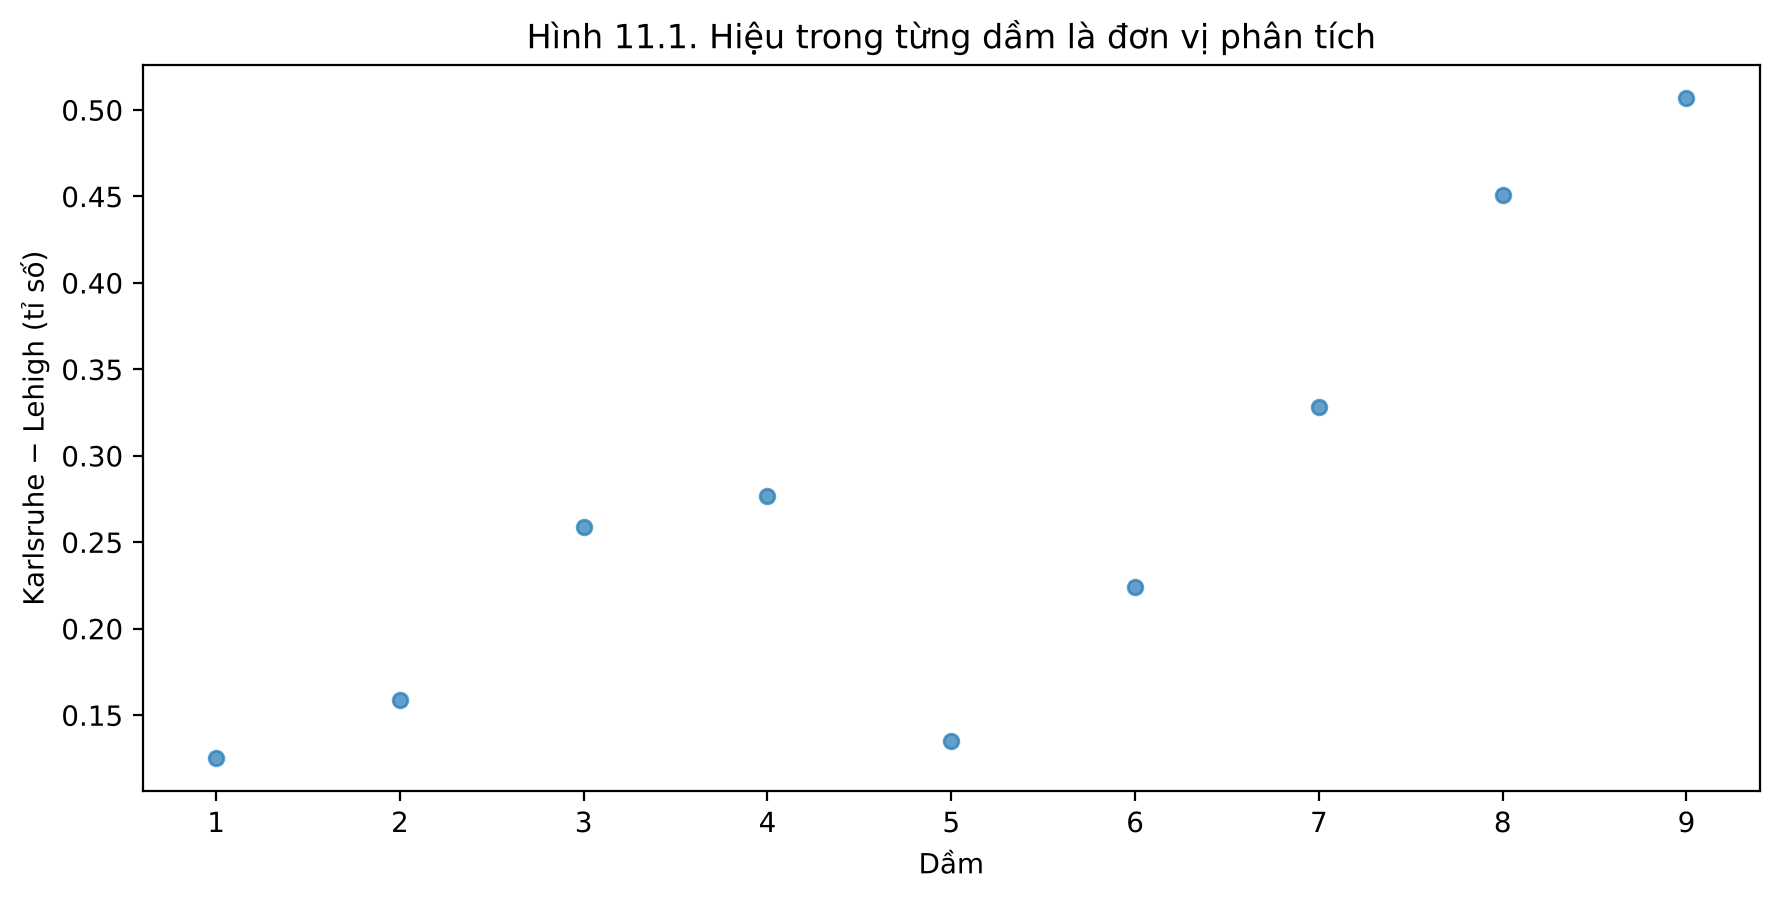

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(paired['beam'], paired['difference'], s=28, alpha=0.7)
ax.set(xlabel='Dầm', ylabel='Karlsruhe − Lehigh (tỉ số)', title='Hình 11.1. Hiệu trong từng dầm là đơn vị phân tích')
fig.tight_layout()
plt.show()

`stats.ttest_rel(x, y)` kiểm định trung bình của dãy hiệu `x - y` bằng 0. Hai mảng phải giữ **đúng thứ tự ghép cặp**: phần tử thứ $i$ của hai mảng là cùng một dầm.

**Thử đổi.** (1) Đổi thành `ttest_rel(lehigh, karlsruhe)`: $t$ đổi dấu, giá trị p hai phía giữ nguyên. (2) Thử `stats.ttest_ind(karlsruhe, lehigh)`, tức coi hai cột là hai mẫu độc lập: $t$ nhỏ đi nhiều, vì khác biệt lớn giữa các dầm bị tính vào sai số. Đó là lý do không được bỏ qua cấu trúc cặp.

### Miền bác bỏ cho từng loại $H_1$

Ô dưới dựng mật độ của bốn phân phối đã dùng ($z$; $t$ với 14; 13,2; 8 bậc tự do), mỗi phân phối với ba loại $H_1$, rồi tô miền bác bỏ 5%.

In [7]:
curves=[]
for name,dist in [('z',stats.norm),('t gộp, df=14',stats.t(14)),
                  ('Welch, df≈13,2',stats.t(df_w)),('t cặp, df=8',stats.t(8))]:
    grid=np.linspace(-4,4,501); crit=dist.ppf(.975)
    for direction in ['Hai phía','Phải','Trái']:
        if direction=='Hai phía':tail=np.abs(grid)>=crit
        elif direction=='Phải':tail=grid>=dist.ppf(.95)
        else:tail=grid<=dist.ppf(.05)
        curves.append(pd.DataFrame({'t':grid,'density':dist.pdf(grid),
            'region':np.where(tail,'Miền bác bỏ','Giữa'),'panel':name+' / '+direction}))
rejection_curves=pd.concat(curves,ignore_index=True)

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Matplotlib.** Dữ liệu vẽ lấy từ bảng `rejection_curves`: trục ngang là cột `t`, trục đứng là cột `density`. `plt.subplots(nrows, ncols)` tạo một lưới hệ trục; vòng `for ax, (panel, part) in zip(...)` vẽ mỗi giá trị của `panel` vào một ô. Mỗi ô có thang trục riêng, nên so các ô bằng số trên trục. Vòng `for label, part_g in ....groupby('region')` vẽ lần lượt từng nhóm của cột `region`; `label=` đặt tên nhóm và `ax.legend()` hiện chú giải. `ax.plot(x, y)` nối các điểm theo thứ tự trong bảng. Cột phụ `_segment` tách từng đoạn liên tiếp của cùng một vùng để hai đuôi không bị nối qua phần giữa; `fill_between` tô các vùng ở đuôi.

**Đọc hình.** Mỗi hàng là một phân phối, mỗi cột một loại $H_1$. Ở cột “Hai phía”, mỗi đuôi chứa 2,5%; ở “Phải” hoặc “Trái”, cả 5% dồn về một đuôi, nên ngưỡng gần 0 hơn (1,645 thay vì 1,96 với $z$). So các hàng: $t$ với ít bậc tự do có đuôi dày hơn, ngưỡng xa 0 hơn.

<!-- branch-plot-instructions: end -->

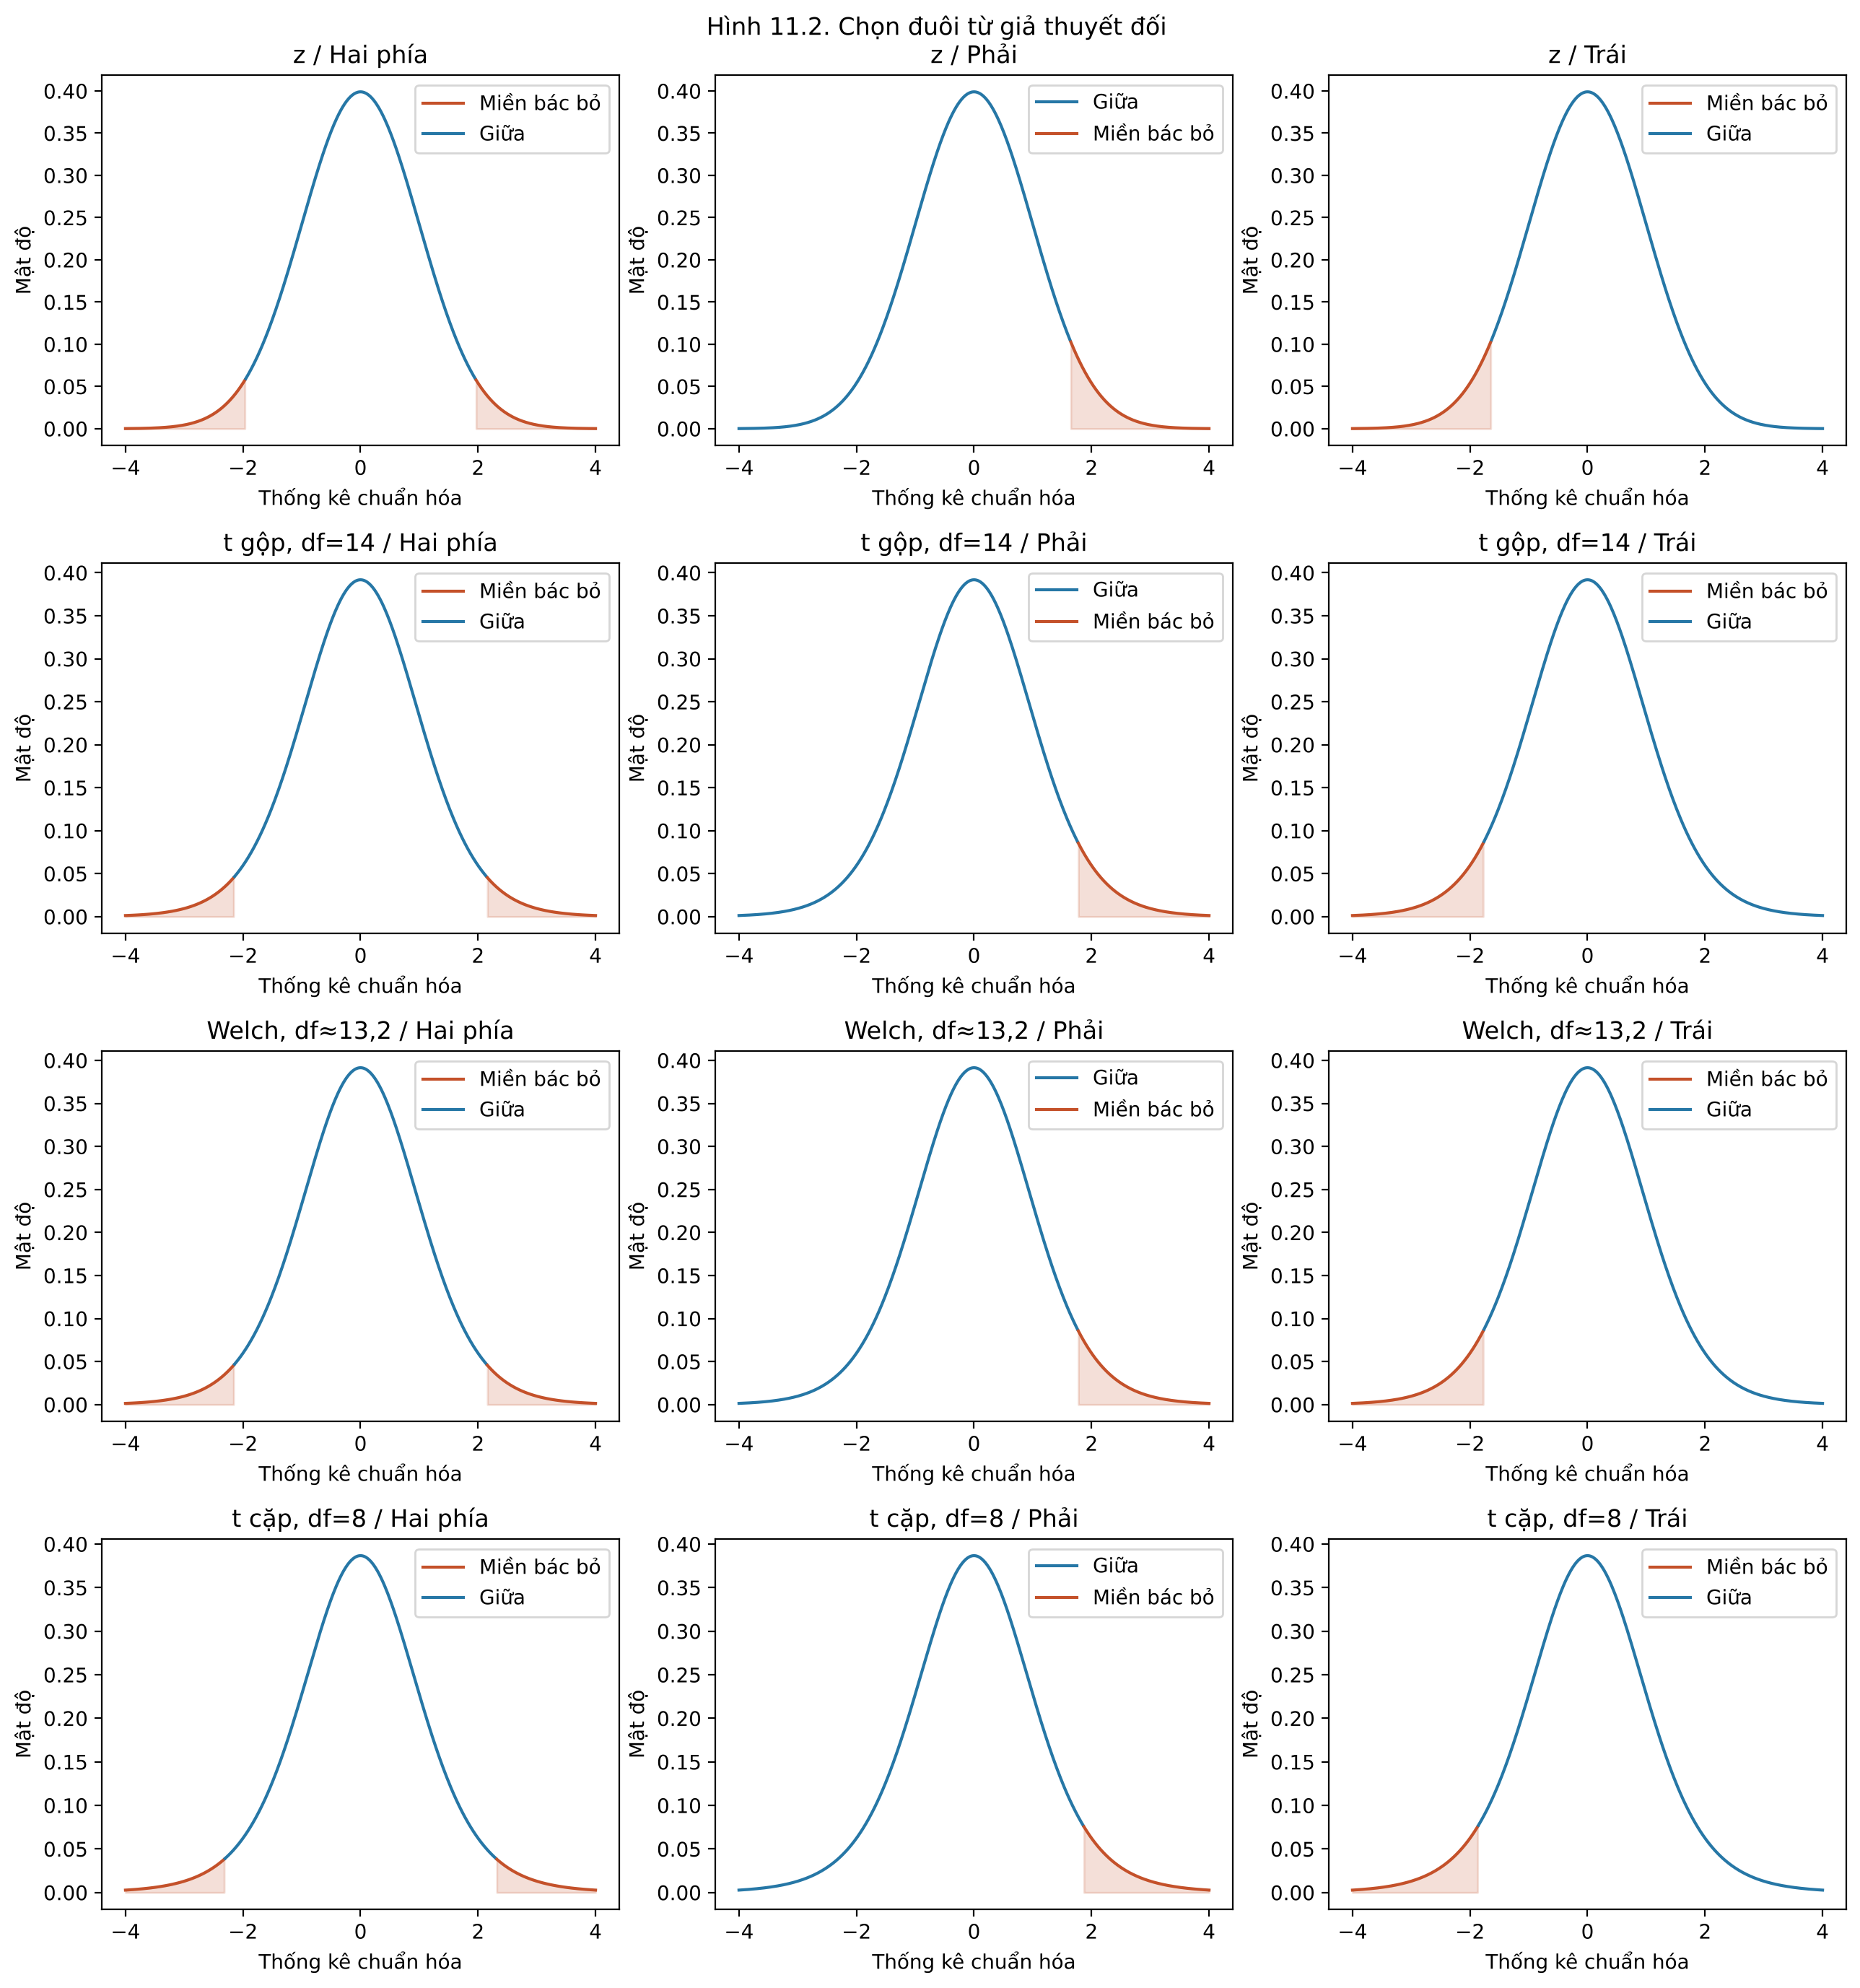

In [8]:
panels = list(rejection_curves.groupby('panel', observed=True, sort=False))
ncols = min(3, len(panels))
nrows = int(np.ceil(len(panels)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3*ncols, 3.5*nrows), squeeze=False)
for ax in axes.flat[len(panels):]:
    ax.set_visible(False)
for ax, (panel, part) in zip(axes.flat, panels):
    line_data = part.copy()
    line_data['_segment'] = line_data.region.ne(line_data.region.shift()).cumsum()
    seen_labels = set()
    for segment, part_g in line_data.groupby('_segment', sort=False):
        label = str(part_g.region.iloc[0])
        region_color = '#2677A6' if label in ['Giữa','Còn lại','Phần còn lại'] else '#C4512A'
        ax.plot(part_g['t'], part_g['density'], linewidth=1.5, color=region_color, label=label if label not in seen_labels else None)
        seen_labels.add(label)
        if label not in ['Giữa','Còn lại','Phần còn lại']:
            ax.fill_between(part_g['t'], part_g['density'], alpha=0.18, color=region_color)
    ax.legend()
    ax.set(xlabel='Thống kê chuẩn hóa', ylabel='Mật độ', title='Hình 11.2. Chọn đuôi từ giả thuyết đối',
           )
    ax.set_title(str(panel))
fig.suptitle('Hình 11.2. Chọn đuôi từ giả thuyết đối')
fig.tight_layout()
plt.show()

Với giả thuyết một phía, một hiệu quan sát nằm **ngược** hướng $H_1$ không bao giờ cho giá trị p nhỏ, dù nó lớn đến đâu. Ví dụ: nếu đặt $H_1:\mu_1>\mu_2$ mà quan sát $\bar x_1-\bar x_2<0$, giá trị p lớn hơn 0,5.

<a id="muc-3"></a>

## 3. Hai tỉ lệ: dùng tỉ lệ chung dưới H₀

### Bài toán

Hai mẫu độc lập cỡ $n_1$, $n_2$; số đơn vị có đặc điểm cần xét là $x_1$, $x_2$. Tỉ lệ mẫu $\hat p_1=x_1/n_1$, $\hat p_2=x_2/n_2$. Giả thuyết hai phía: $H_0: p_1=p_2$, $H_1: p_1\ne p_2$ (một phía nếu hướng đã định trước).

### Thống kê

**Nếu $H_0$ đúng, hai nhóm có chung một tỉ lệ $p$.** Ước lượng tốt nhất cho tỉ lệ chung đó là gộp hai mẫu lại:
$$\hat p_{pool}=\frac{x_1+x_2}{n_1+n_2}.$$
Dùng nó trong sai số chuẩn:
$$z=\frac{\hat p_1-\hat p_2}{\sqrt{\hat p_{pool}(1-\hat p_{pool})\Big(\dfrac1{n_1}+\dfrac1{n_2}\Big)}}.$$
Đọc là: hiệu hai tỉ lệ chia cho sai số chuẩn **tính trong thế giới $H_0$**, nơi hai nhóm có cùng tỉ lệ. Đây là cùng ý với Tuần 10: kiểm định tính SE theo giả thuyết, không theo dữ liệu.

Khi $H_0$ đúng và cỡ mẫu đủ lớn, $z$ xấp xỉ chuẩn tắc. Quy tắc bác bỏ như bảng ở mục 2.

### Điều kiện

- Hai mẫu chọn ngẫu nhiên và độc lập.
- Cả bốn số $n_1\hat p_1$, $n_1(1-\hat p_1)$, $n_2\hat p_2$, $n_2(1-\hat p_2)$ đều $\ge10$.

Khoảng tin cậy cho $p_1-p_2$ (không thuộc buổi này) dùng SE **không gộp**, $\sqrt{\hat p_1(1-\hat p_1)/n_1+\hat p_2(1-\hat p_2)/n_2}$, vì khi lập khoảng ta không giả định hai tỉ lệ bằng nhau.

### Ví dụ 5 — Tỉ lệ sản phẩm lỗi của hai dây chuyền

Một nhà máy sản xuất cùng loại linh kiện trên hai dây chuyền A và B, muốn biết tỉ lệ lỗi dài hạn của hai dây chuyền có khác nhau không. Chọn ngẫu nhiên, độc lập 200 sản phẩm từ A và 220 từ B: A có 18 lỗi, B có 32 lỗi. Ở mức 5%, kiểm định giả thuyết hai dây chuyền có cùng tỉ lệ lỗi; nêu kết luận trong bối cảnh sản xuất.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* $p_A, p_B$: tỉ lệ lỗi dài hạn. $H_0: p_A=p_B$, $H_1: p_A\ne p_B$.

*Bước 2: tỉ lệ mẫu và tỉ lệ gộp.*
$$\hat p_A=\frac{18}{200}=0{,}09,\qquad \hat p_B=\frac{32}{220}\approx0{,}1455,\qquad \hat p_{pool}=\frac{18+32}{200+220}=\frac{50}{420}\approx0{,}1190.$$

*Bước 3: điều kiện.* Số lỗi và không lỗi: A có 18 và 182, B có 32 và 188; cả bốn đều $\ge10$.

*Bước 4: thống kê.*
$$SE=\sqrt{0{,}1190\times0{,}8810\times\Big(\frac1{200}+\frac1{220}\Big)}\approx0{,}0316,\qquad z=\frac{0{,}09-0{,}1455}{0{,}0316}\approx-1{,}75.$$

*Bước 5: quyết định.* Giá trị p $=2P(Z>1{,}75)\approx0{,}080>0{,}05$: không bác bỏ $H_0$.

*Kết luận.* Chưa đủ bằng chứng để kết luận tỉ lệ lỗi dài hạn của hai dây chuyền khác nhau. Kết quả **không** khẳng định hai tỉ lệ bằng nhau: mẫu hiện có cho chênh lệch 5,5 điểm phần trăm, nhưng với cỡ mẫu này chênh lệch đó chưa vượt rõ mức dao động ngẫu nhiên.

</details>

In [9]:
from statsmodels.stats.proportion import proportions_ztest
pool=50/420
se_pool=np.sqrt(pool*(1-pool)*(1/200+1/220))
z_defect=(18/200-32/220)/se_pool
print('Tự tính:',z_defect,2*stats.norm.sf(abs(z_defect)))
print('Statsmodels:',proportions_ztest([18,32],[200,220]))
print('Số đếm kỳ vọng H₀:',[200*pool,200*(1-pool),220*pool,220*(1-pool)])

Tự tính: -1.752678539801884 0.07965720137831742
Statsmodels: (np.float64(-1.752678539801884), np.float64(0.07965720137831742))
Số đếm kỳ vọng H₀: [23.809523809523807, 176.19047619047618, 26.19047619047619, 193.8095238095238]


`proportions_ztest([18, 32], [200, 220])` nhận số "thành công" và cỡ mẫu của hai nhóm, dùng tỉ lệ gộp, trả về $z$ và giá trị p hai phía. Dòng cuối in số lỗi/không lỗi **kỳ vọng dưới $H_0$** (khoảng 24, 176, 26, 194): cũng đều lớn, nên xấp xỉ chuẩn ổn.

"Thành công" ở đây là **sản phẩm lỗi**: chỉ là tên của loại được đếm, không có nghĩa là điều mong muốn. Nếu đếm sản phẩm không lỗi, $z$ đổi dấu nhưng giá trị p hai phía giữ nguyên.

<a id="muc-4"></a>

## 4. So sánh hai phương sai — tự chọn

### Khi nào quan tâm đến phương sai?

Hai máy A và B cùng gia công một loại chi tiết. Ngoài kích thước trung bình đúng yêu cầu, nhà máy còn cần chi tiết **đồng đều**: máy có phương sai sai số nhỏ hơn cho sản phẩm ổn định hơn. Câu hỏi: $H_0:\sigma_A^2=\sigma_B^2$, $H_1:\sigma_A^2\ne\sigma_B^2$.

### Thống kê $F$

Lấy hai mẫu độc lập cỡ $n_1$, $n_2$ từ hai tổng thể **chuẩn**:
$$F=\frac{S_1^2}{S_2^2}.$$
Khi $H_0$ đúng, $F$ có phân phối $F$ với hai bậc tự do $(\nu_1,\nu_2)=(n_1-1,\ n_2-1)$, viết theo đúng thứ tự tử–mẫu. Phân phối $F$ chỉ nhận giá trị dương và lệch phải. Dưới $H_0$, $F$ dao động quanh 1.

**Quy tắc bác bỏ hai phía.** Bác bỏ khi $f$ quá nhỏ hoặc quá lớn: $f<f_{1-\alpha/2}$ hoặc $f>f_{\alpha/2}$, với $P(F>f_\gamma)=\gamma$. Tương đương:
$$\text{giá trị p}=2\min\big\{P(F\le f),\ P(F\ge f)\big\}.$$
Lấy hai lần đuôi **nhỏ hơn**. Không cần đặt phương sai lớn hơn lên tử số, miễn là giữ đúng thứ tự hai bậc tự do.

**Kiểm định $F$ rất nhạy với giả định chuẩn.** Nếu dữ liệu lệch hoặc có đuôi dày, giá trị p có thể sai nhiều. Vì vậy không nên dùng kiểm định $F$ làm "bước bắt buộc" để quyết định dùng $t$ gộp hay Welch; khi không có lý do để tin phương sai bằng nhau, cứ dùng Welch.

### Ví dụ 6 — Độ ổn định của hai máy

Để đánh giá độ đồng đều kích thước của hai máy, bộ phận chất lượng chọn ngẫu nhiên, độc lập 16 sản phẩm từ máy A và 14 từ máy B. Phương sai mẫu của sai số kích thước là $s_A^2=2{,}89$ và $s_B^2=1{,}44$ (đơn vị bình phương). Giả sử sai số kích thước mỗi máy có phân phối chuẩn. Ở mức 5%, có đủ bằng chứng để kết luận phương sai sai số hai máy khác nhau không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* $H_0:\sigma_A^2=\sigma_B^2$, $H_1:\sigma_A^2\ne\sigma_B^2$.

*Bước 2: thống kê.* $f=2{,}89/1{,}44\approx2{,}007$, với $(\nu_1,\nu_2)=(15,13)$.

*Bước 3: ngưỡng.* Với $F_{15,13}$, $f_{0{,}975}\approx0{,}342$ và $f_{0{,}025}\approx3{,}053$. Hai ngưỡng **không** cách đều 1 vì phân phối lệch phải. $f=2{,}007$ nằm giữa hai ngưỡng.

*Bước 4: giá trị p.* $P(F\ge2{,}007)\approx0{,}107$ (đuôi nhỏ hơn), nên giá trị p $\approx2\times0{,}107=0{,}214>0{,}05$. Không bác bỏ $H_0$.

*Kết luận.* Phương sai mẫu của A gấp đôi B, nhưng với 16 và 14 sản phẩm, chênh lệch cỡ này chưa đủ bằng chứng để kết luận mức biến động của hai máy khác nhau. Kết quả không khẳng định hai phương sai bằng nhau.

</details>

In [10]:
f_obs=2.89/1.44
f_dist=stats.f(15,13)
print('F:',f_obs,'p:',min(1,2*min(f_dist.cdf(f_obs),f_dist.sf(f_obs))))
f_grid=np.linspace(.01,5,700)
f_plot=pd.DataFrame({'f':f_grid,'density':f_dist.pdf(f_grid),
    'region':np.where((f_grid<f_dist.ppf(.025))|(f_grid>f_dist.ppf(.975)),'Hai đuôi','Giữa')})
print('Ngưỡng:',f_dist.ppf([.025,.975]))

F: 2.0069444444444446 p: 0.21435479574403826
Ngưỡng: [0.34189151 3.05271325]


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Matplotlib.** Dữ liệu vẽ lấy từ bảng `f_plot`: trục ngang là cột `f`, trục đứng là cột `density`. Vòng `for label, part_g in ....groupby('region')` vẽ lần lượt từng nhóm của cột `region`; `label=` đặt tên nhóm và `ax.legend()` hiện chú giải. `ax.plot(x, y)` nối các điểm theo thứ tự trong bảng. Cột phụ `_segment` tách từng đoạn liên tiếp của cùng một vùng để hai đuôi không bị nối qua phần giữa; `fill_between` tô các vùng ở đuôi. `ax.axvline(...)` vẽ đường đứt đoạn tại `f_obs`.

**Đọc hình.** Đường cong $F_{15,13}$ có đỉnh gần 1 và đuôi phải dài. Đuôi trái chỉ là một mẩu ngắn từ 0 đến 0,34; đuôi phải từ 3,05 trở đi. Mỗi đuôi chứa đúng 2,5% diện tích dù dài ngắn khác nhau. Đường đứt đoạn $f=2{,}007$ nằm trong vùng giữa.

<!-- branch-plot-instructions: end -->

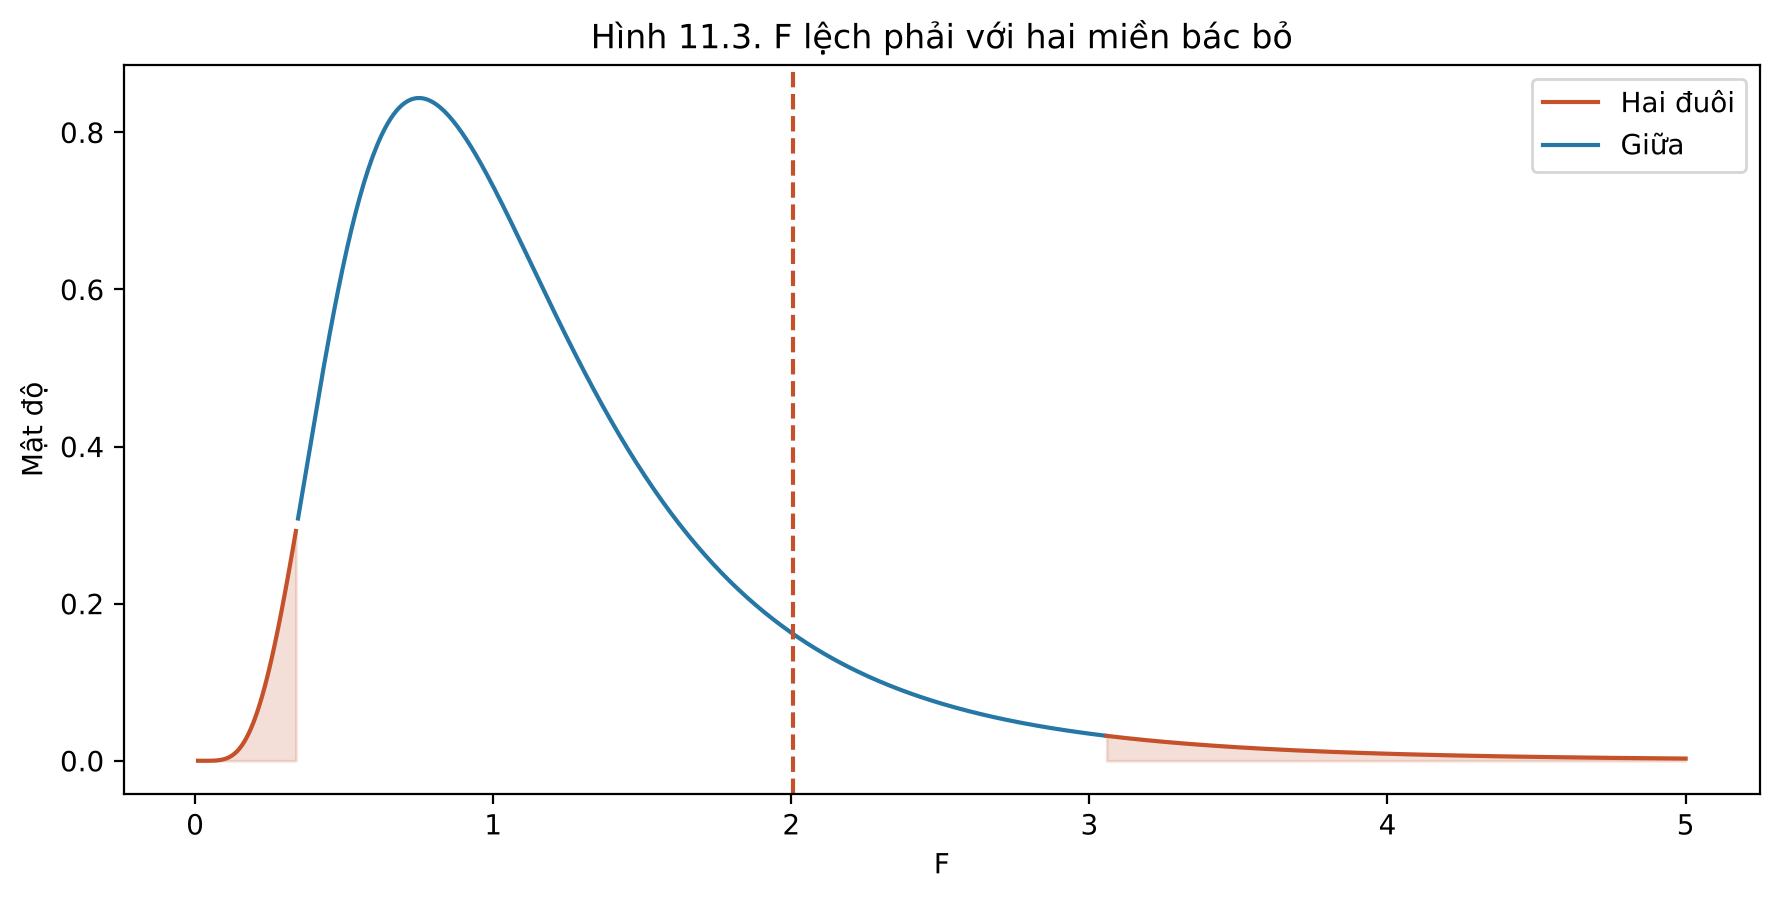

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
line_data = f_plot.copy()
line_data['_segment'] = line_data.region.ne(line_data.region.shift()).cumsum()
seen_labels = set()
for segment, part_g in line_data.groupby('_segment', sort=False):
    label = str(part_g.region.iloc[0])
    region_color = '#2677A6' if label in ['Giữa','Còn lại','Phần còn lại'] else '#C4512A'
    ax.plot(part_g['f'], part_g['density'], linewidth=1.5, color=region_color, label=label if label not in seen_labels else None)
    seen_labels.add(label)
    if label not in ['Giữa','Còn lại','Phần còn lại']:
        ax.fill_between(part_g['f'], part_g['density'], alpha=0.18, color=region_color)
ax.axvline(f_obs, color='#C4512A', linestyle='--')
ax.legend()
ax.set(xlabel='F', ylabel='Mật độ', title='Hình 11.3. F lệch phải với hai miền bác bỏ')
fig.tight_layout()
plt.show()

Hai miền bác bỏ chia đều **xác suất** (2,5% mỗi bên), không chia đều **khoảng cách** quanh 1. Đó là lý do tính giá trị p bằng hai lần đuôi nhỏ hơn, thay vì đo $f$ cách 1 bao xa.

<a id="muc-5"></a>

## 5. χ² độ phù hợp: xét cả phân phối

### Bài toán

Một biến phân loại có $k$ nhóm. Từ $n$ quan sát độc lập, ta muốn biết tỉ lệ các nhóm có khớp với một phân phối **cho trước** không. Gọi $p_i$ là tỉ lệ thật của nhóm $i$, $p_{i0}$ là tỉ lệ theo mô hình:
$$H_0: p_i=p_{i0}\ \text{với mọi } i=1,\ldots, k;\qquad H_1:\text{có ít nhất một } p_i\ne p_{i0}.$$
Các nhóm phải loại trừ nhau và bao quát mọi kết quả, nên $\sum_i p_{i0}=1$.

### Thống kê Pearson

Gọi $O_i$ là tần số quan sát của nhóm $i$. Nếu $H_0$ đúng, tần số **kỳ vọng** là $E_i=np_{i0}$. Thống kê
$$Q=\sum_{i=1}^k\frac{(O_i-E_i)^2}{E_i}.$$
Đọc là: với mỗi nhóm, lấy chênh lệch giữa quan sát và kỳ vọng, bình phương lên, chia cho kỳ vọng, rồi cộng tất cả. Chia cho $E_i$ để một chênh lệch 10 ở nhóm kỳ vọng 20 được tính nặng hơn chênh lệch 10 ở nhóm kỳ vọng 200.

Mọi số hạng đều không âm. Lệch theo hướng nào cũng làm $Q$ **tăng**, nên miền bác bỏ chỉ ở **đuôi phải**, dù $H_1$ là "khác ở đâu đó".

### Phân phối dưới $H_0$

Nếu các $p_{i0}$ được cho trước (không ước lượng từ dữ liệu) và các $E_i$ đủ lớn, thì
$$Q\ \overset{\text{xấp xỉ}}{\sim}\ \chi^2_{k-1}.$$
Bậc tự do là $k-1$ chứ không phải $k$ vì các $O_i$ bị ràng buộc cộng lại bằng $n$: biết $k-1$ nhóm là biết nhóm cuối. Nếu phải ước lượng tham số của mô hình từ chính dữ liệu, bậc tự do giảm thêm.

**Quy tắc.** Bác bỏ $H_0$ khi $q>\chi^2_{\alpha,\, k-1}$, hay giá trị p $=P(\chi^2_{k-1}\ge q)<\alpha$.

**Điều kiện.** Các quan sát độc lập; mỗi quan sát thuộc đúng một nhóm; mọi **tần số kỳ vọng** $E_i\ge5$.

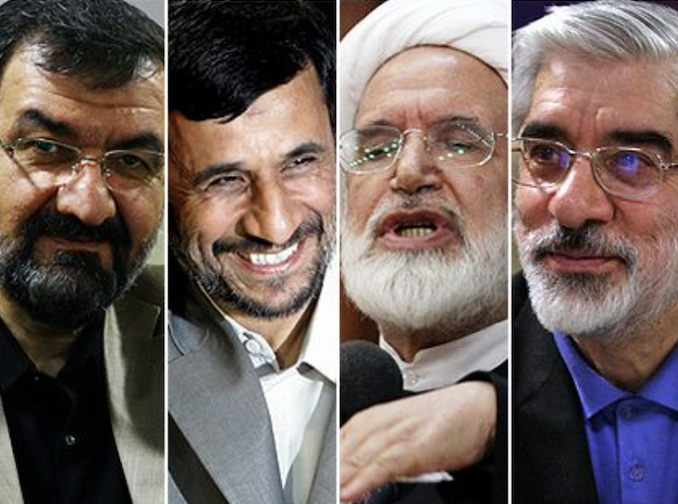

*Hình tham khảo 11.27: Các ứng viên trong bối cảnh ví dụ chữ số đầu. Nguồn: STAT 20 bản dịch tiếng Việt, mục 5.5, hình nhúng trong học liệu gốc.*

Ảnh cho bối cảnh của Ví dụ 7. Phép kiểm định chỉ so số đếm chữ số với một mô hình; nó không xác định nguyên nhân của sai khác.

### Ví dụ 7 — Chữ số đầu của số phiếu bầu

Trong bầu cử tổng thống Iran năm 2009, số phiếu của mỗi ứng viên được công bố theo địa phương. Xét số phiếu của ứng viên Mehdi Karroubi tại 366 địa phương. Chữ số đầu tiên của các số phiếu:

| Chữ số đầu $d$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| Số địa phương $O_d$ | 125 | 57 | 44 | 29 | 24 | 16 | 41 | 13 | 17 |

Một mô hình được đề xuất cho chữ số đầu là **luật Benford**: $p_{d0}=\log_{10}(1+1/d)$, $d=1,\ldots,9$. Ở mức 5%, phân phối chữ số đầu có phù hợp với mô hình Benford không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* $H_0: p_d=\log_{10}(1+1/d)$ với mọi $d$; $H_1$: có ít nhất một tỉ lệ khác mô hình.

*Bước 2: tần số kỳ vọng và đóng góp.* $E_d=366\log_{10}(1+1/d)$. Ví dụ $E_1=366\log_{10}2\approx110{,}2$.

| $d$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| $E_d$ | 110,18 | 64,45 | 45,73 | 35,47 | 28,98 | 24,50 | 21,23 | 18,72 | 16,75 |
| $(O_d-E_d)^2/E_d$ | 1,99 | 0,86 | 0,07 | 1,18 | 0,86 | 2,95 | 18,42 | 1,75 | 0,00 |

*Bước 3: điều kiện.* $E$ nhỏ nhất là $E_9\approx16{,}75\ge5$. Mô hình coi chữ số ở các địa phương khác nhau là độc lập.

*Bước 4: thống kê.* $q=\sum\approx28{,}08$, $df=9-1=8$.

*Bước 5: quyết định.* $\chi^2_{0{,}05,\,8}\approx15{,}51$. Vì $28{,}08>15{,}51$, bác bỏ $H_0$; giá trị p $\approx0{,}00046$.

*Kết luận.* Ở mức 5%, phân phối chữ số đầu không phù hợp với mô hình Benford theo các giả định đã nêu. Gần 2/3 giá trị $Q$ đến từ chữ số 7 (41 địa phương, kỳ vọng 21).

*Kết luận này **không** đủ để nói có gian lận.* Một mô hình không khớp chỉ cho biết mô hình đó sai với dữ liệu này; nó không chỉ ra nguyên nhân. Muốn dùng Benford làm thước đo, trước hết phải biện luận vì sao số phiếu theo địa phương *nên* tuân theo Benford (luật này đúng với những số trải trên nhiều bậc độ lớn, điều không phải lúc nào cũng thỏa với số phiếu của một ứng viên ít phiếu), và vì sao các địa phương độc lập.

</details>

In [12]:
observed=np.array([125,57,44,29,24,16,41,13,17])
digit=np.arange(1,10)
expected=observed.sum()*np.log10(1+1/digit)
contributions=(observed-expected)**2/expected
q_ben=contributions.sum(); p_ben=stats.chi2.sf(q_ben,8)
display(pd.DataFrame({'Chữ số':digit,'O':observed,'E':expected,'Đóng góp Q':contributions}))
print('Q, p:',q_ben,p_ben,'; SciPy:',stats.chisquare(observed,expected))
ben_plot=pd.concat([pd.DataFrame({'digit':digit,'count':v,'kind':name})
    for name,v in [('Quan sát',observed),('Kỳ vọng Benford',expected)]])
assert np.isclose(q_ben,stats.chisquare(observed,expected).statistic)

,Chữ số,O,E,Đóng góp Q
0,1,125,110.17698,1.99426
1,2,57,64.44940,0.86104
2,3,44,45.72758,0.06527
3,4,29,35.46906,1.17987
4,5,24,28.98034,0.85588
5,6,16,24.50253,2.95043
6,7,41,21.22505,18.42391
7,8,13,18.72182,1.74872
8,9,17,16.74724,0.00381


Q, p: 28.08320032485336 0.00045868441326063307 ; SciPy: Power_divergenceResult(statistic=np.float64(28.08320032485336), pvalue=np.float64(0.00045868441326063307))


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Matplotlib.** Dữ liệu vẽ lấy từ bảng `ben_plot`: trục ngang là cột `digit`, trục đứng là cột `count`. Vòng `for label, part_g in ....groupby('kind')` vẽ lần lượt từng nhóm của cột `kind`; `label=` đặt tên nhóm và `ax.legend()` hiện chú giải. `ax.bar(...)` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn; khi có nhiều nhóm, mỗi nhóm được dịch sang ngang một chút để các cột đứng cạnh nhau.

**Đọc hình.** Với mỗi chữ số có hai cột: quan sát và kỳ vọng. Chữ số 7 có cột quan sát gần gấp đôi cột kỳ vọng. Ở các chữ số khác, hai cột chênh nhau ít.

<!-- branch-plot-instructions: end -->

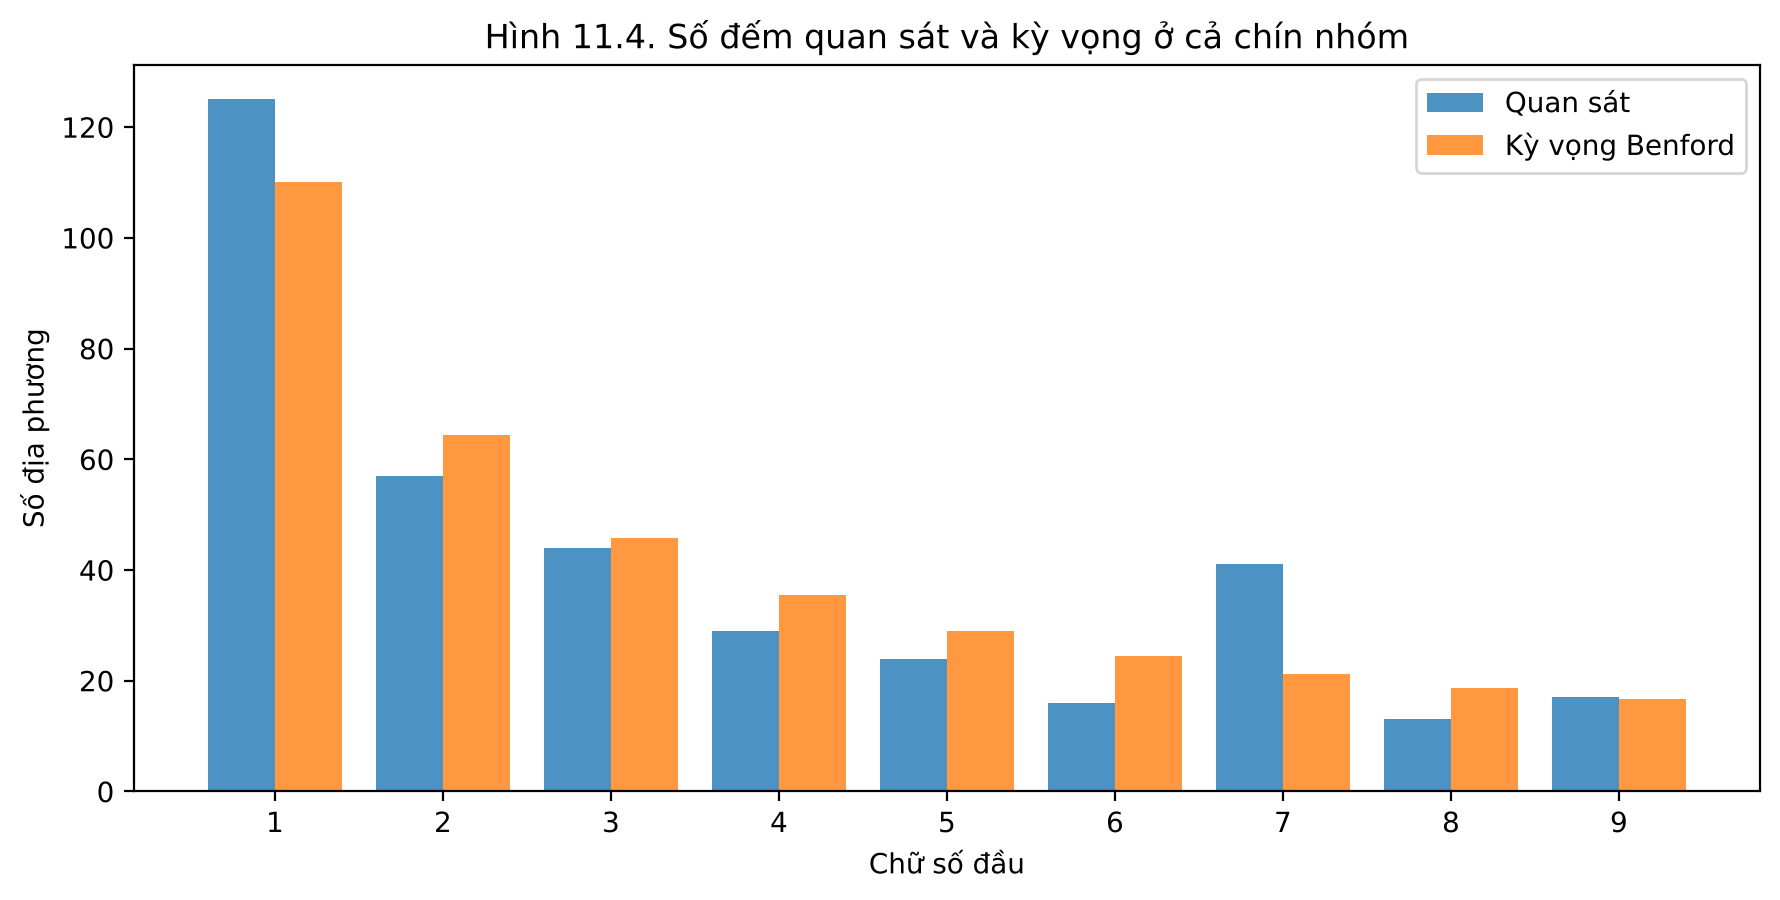

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.6))
categories = list(pd.unique(ben_plot['digit']))
positions = {value:i for i,value in enumerate(categories)}
groups = list(ben_plot.groupby('kind', observed=True, sort=False))
shared_x = ben_plot.groupby('digit')['kind'].nunique().max()>1
bar_width = 0.8/len(groups) if shared_x else 0.8
for group_idx, (label, part_g) in enumerate(groups):
    ax.bar(part_g['digit'].map(positions)+(group_idx-(len(groups)-1)/2)*bar_width*shared_x, part_g['count'], width=bar_width, alpha=0.8, label=str(label))
tick_step = max(1, int(np.ceil(len(categories)/12)))
tick_idx = np.arange(0,len(categories),tick_step)
tick_labels = [f'{categories[i]:.3g}' if isinstance(categories[i], (int,float,np.number)) else str(categories[i]) for i in tick_idx]
ax.set_xticks(tick_idx, labels=tick_labels)
ax.legend()
ax.set(xlabel='Chữ số đầu', ylabel='Số địa phương', title='Hình 11.4. Số đếm quan sát và kỳ vọng ở cả chín nhóm')
fig.tight_layout()
plt.show()

`stats.chisquare(observed, expected)` nhận tần số quan sát và kỳ vọng (`f_exp`), trả về $Q$ và giá trị p với $df=k-1$.

Chữ số 7 lệch nhiều nhất, nhưng kiểm định đã dùng **cả chín nhóm** như câu hỏi đặt ra từ đầu. Nếu nhìn bảng, thấy chữ số 7 lạ rồi mới kiểm định riêng chữ số 7, ta đã đổi câu hỏi sau khi xem dữ liệu, và xác suất sai lầm loại I không còn là 5%.

Ô dưới vẽ đường $\chi^2_8$ với miền bác bỏ 5%. Ô cũng mô phỏng 5.000 bộ số đếm từ mô hình Benford (`rng.multinomial(366, p, size=5000)`: mỗi lần chia 366 địa phương vào 9 nhóm theo xác suất Benford) và tính $Q$ cho từng bộ, để thấy $Q$ dưới $H_0$ thường nhỏ đến đâu. Phân phối $\chi^2_8$ là xấp xỉ của phân phối mô phỏng này.

In [14]:
chi_grid=np.linspace(.001,35,700)
chi_curve=pd.DataFrame({'q':chi_grid,'density':stats.chi2.pdf(chi_grid,8),
    'region':np.where(chi_grid>=stats.chi2.ppf(.95,8),'Bác bỏ 5%','Giữa')})
# Bổ sung mô phỏng theo mô hình đa thức H₀ để nhìn nguồn gốc Q.
null_counts=rng.multinomial(366,expected/366,size=5000)
null_q=((null_counts-expected)**2/expected).sum(axis=1)
print('Đuôi mô phỏng:',(1+(null_q>=q_ben).sum())/(len(null_q)+1))

Đuôi mô phỏng: 0.0009998000399920016


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Matplotlib.** Dữ liệu vẽ lấy từ bảng `chi_curve`: trục ngang là cột `q`, trục đứng là cột `density`. Vòng `for label, part_g in ....groupby('region')` vẽ lần lượt từng nhóm của cột `region`; `label=` đặt tên nhóm và `ax.legend()` hiện chú giải. `ax.plot(x, y)` nối các điểm theo thứ tự trong bảng. Cột phụ `_segment` tách từng đoạn liên tiếp của cùng một vùng để hai đuôi không bị nối qua phần giữa; `fill_between` tô các vùng ở đuôi. `ax.axvline(...)` vẽ đường đứt đoạn tại `q_ben`.

**Đọc hình.** Phân phối $\chi^2_8$ có đỉnh gần 6 và tâm (kỳ vọng) bằng 8, đúng bằng số bậc tự do. Miền bác bỏ bắt đầu từ 15,51. Đường đứt đoạn $q=28{,}08$ nằm sâu trong đuôi phải.

<!-- branch-plot-instructions: end -->

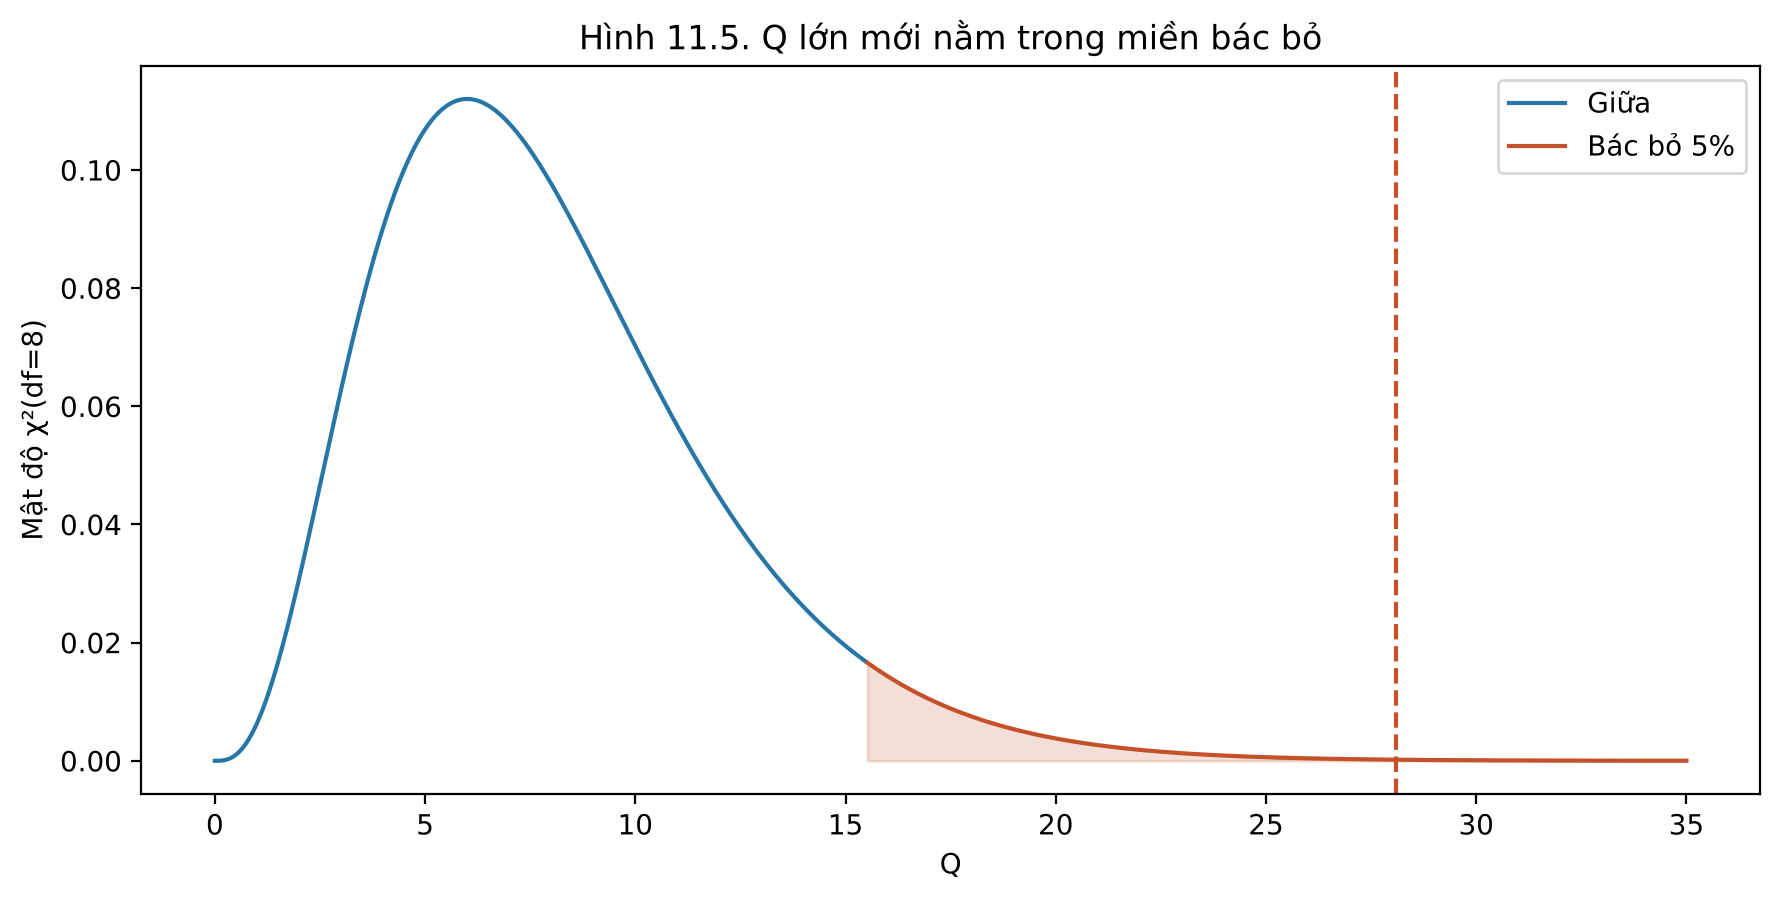

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.6))
line_data = chi_curve.copy()
line_data['_segment'] = line_data.region.ne(line_data.region.shift()).cumsum()
seen_labels = set()
for segment, part_g in line_data.groupby('_segment', sort=False):
    label = str(part_g.region.iloc[0])
    region_color = '#2677A6' if label in ['Giữa','Còn lại','Phần còn lại'] else '#C4512A'
    ax.plot(part_g['q'], part_g['density'], linewidth=1.5, color=region_color, label=label if label not in seen_labels else None)
    seen_labels.add(label)
    if label not in ['Giữa','Còn lại','Phần còn lại']:
        ax.fill_between(part_g['q'], part_g['density'], alpha=0.18, color=region_color)
ax.axvline(q_ben, color='#C4512A', linestyle='--')
ax.legend()
ax.set(xlabel='Q', ylabel='Mật độ χ²(df=8)', title='Hình 11.5. Q lớn mới nằm trong miền bác bỏ')
fig.tight_layout()
plt.show()

Với 5.000 lần mô phỏng, độ phân giải của giá trị p chỉ cỡ $1/5000=0{,}0002$, nên con số in ra (có hiệu chỉnh $(b+1)/(B+1)$ như Tuần 10) chỉ khớp $p\approx0{,}00046$ ở mức độ lớn. Mô phỏng thể hiện đúng mô hình số đếm của $H_0$; công thức $\chi^2$ là xấp xỉ của nó khi các $E_i$ đủ lớn.

<a id="muc-6"></a>

## 6. χ² tính độc lập: từ bảng O sang bảng E

### Bài toán

Trên **cùng một mẫu** $n$ đối tượng, ghi nhận hai biến phân loại, ví dụ hình thức trả lương và gói bảo hiểm của mỗi nhân viên. Hai biến có liên hệ trong tổng thể không?
$$H_0:\text{hai biến độc lập};\qquad H_1:\text{hai biến không độc lập}.$$
Xếp số đếm vào bảng chéo $r$ hàng × $c$ cột.

### Tần số kỳ vọng khi độc lập

Nếu hai biến độc lập, tỉ lệ đối tượng rơi vào ô $(i, j)$ bằng (tỉ lệ hàng $i$) × (tỉ lệ cột $j$). Nhân với $n$:
$$E_{ij}=n\cdot\frac{\text{tổng hàng }i}{n}\cdot\frac{\text{tổng cột }j}{n}=\frac{(\text{tổng hàng }i)(\text{tổng cột }j)}{n}.$$

### Thống kê và bậc tự do

$$Q=\sum_{i=1}^r\sum_{j=1}^c\frac{(O_{ij}-E_{ij})^2}{E_{ij}}\ \overset{\text{xấp xỉ}}{\sim}\ \chi^2_\nu,\qquad \nu=(r-1)(c-1).$$
Bậc tự do: khi đã biết các tổng hàng và tổng cột, chỉ cần điền $(r-1)(c-1)$ ô là các ô còn lại bị xác định. Miền bác bỏ ở đuôi phải.

### Điều kiện

- Mẫu ngẫu nhiên, các đối tượng độc lập.
- Mỗi đối tượng được đếm **đúng một lần**, trong đúng một ô.
- Mọi **tần số kỳ vọng** $E_{ij}\ge5$ (kiểm tra trên $E$, không phải trên $O$). Bảng quá thưa cần phương pháp khác.

Bác bỏ độc lập chỉ cho biết **có liên hệ**. Nó không nói biến nào gây ra biến nào.

### Ví dụ 8 — Lựa chọn bảo hiểm y tế

Một công ty cân nhắc ba gói bảo hiểm y tế và muốn biết lựa chọn gói có liên hệ với hình thức trả lương không. Công ty chọn ngẫu nhiên 500 nhân viên:

| Hình thức trả lương | Gói 1 | Gói 2 | Gói 3 | Tổng |
|---|---|---|---|---|
| Lương cố định | 160 | 140 | 40 | 340 |
| Lương theo giờ | 40 | 60 | 60 | 160 |
| Tổng | 200 | 200 | 100 | 500 |

Ở mức 5%, kiểm định tính độc lập giữa hình thức trả lương và lựa chọn bảo hiểm.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* $H_0$: hình thức trả lương và lựa chọn bảo hiểm độc lập; $H_1$: có liên hệ.

*Bước 2: bảng kỳ vọng.* Ví dụ $E_{11}=340\times200/500=136$.

| | Gói 1 | Gói 2 | Gói 3 |
|---|---|---|---|
| Lương cố định | 136 | 136 | 68 |
| Lương theo giờ | 64 | 64 | 32 |

$E$ nhỏ nhất là 32 $\ge5$. Kiểm tra: mỗi hàng và cột của bảng $E$ có cùng tổng với bảng $O$.

*Bước 3: đóng góp của từng ô.*

| | Gói 1 | Gói 2 | Gói 3 |
|---|---|---|---|
| Lương cố định | $\frac{(160-136)^2}{136}\approx4{,}24$ | 0,12 | $\frac{(40-68)^2}{68}\approx11{,}53$ |
| Lương theo giờ | $\frac{(40-64)^2}{64}=9{,}00$ | 0,25 | $\frac{(60-32)^2}{32}=24{,}50$ |

$q\approx49{,}63$, $df=(2-1)(3-1)=2$.

*Bước 4: quyết định.* $\chi^2_{0{,}05,\,2}\approx5{,}99$. Vì $49{,}63>5{,}99$, bác bỏ $H_0$; giá trị p $\approx1{,}67\times10^{-11}$.

*Kết luận.* Có bằng chứng rằng lựa chọn gói bảo hiểm có liên hệ với hình thức trả lương trong tổng thể nhân viên công ty. Bảng đóng góp chỉ ra chỗ khác nhiều nhất: nhân viên lương theo giờ chọn gói 3 nhiều hơn hẳn (60 so với kỳ vọng 32), nhân viên lương cố định chọn gói 3 ít hơn.

</details>

In [16]:
O=np.array([[160,140,40],[40,60,60]])
E=O.sum(axis=1)[:,None]*O.sum(axis=0)[None,:]/O.sum()
q_ind=((O-E)**2/E).sum()
print('Q=',q_ind,'p=',stats.chi2.sf(q_ind,2));display(pd.DataFrame(E))
test_ind=stats.chi2_contingency(O,correction=False)
print('SciPy:',test_ind.statistic,test_ind.pvalue,test_ind.dof)
assert np.allclose(E,test_ind.expected_freq)

Q= 49.63235294117647 p= 1.6690582619123915e-11


,0,1,2
0,136.0,136.0,68.0
1,64.0,64.0,32.0


SciPy: 49.63235294117647 1.6690582619123915e-11 2


Dòng `E = O.sum(axis=1)[:, None] * O.sum(axis=0)[None, :] / O.sum()` là công thức $E_{ij}=(\text{tổng hàng})(\text{tổng cột})/n$ viết cho cả bảng cùng lúc: `[:, None]` biến tổng hàng thành một cột, `[None, :]` biến tổng cột thành một hàng, nhân hai cái được bảng $2\times3$.

`stats.chi2_contingency(O, correction=False)` trả về $Q$, giá trị p, bậc tự do và bảng kỳ vọng. `correction=False` để tính đúng thống kê Pearson như slide (không dùng hiệu chỉnh liên tục, vốn chỉ áp dụng cho bảng 2×2).

Sáu ô không phải sáu mẫu độc lập: chúng là cách chia **một** mẫu 500 người. Ràng buộc về tổng hàng và tổng cột đã được tính vào $df=2$.

<a id="muc-7"></a>

## 7. Sai lầm và lực kiểm định là xác suất của quy trình

### Hai loại sai lầm

Ngay cả khi làm đúng mọi bước, kiểm định vẫn có thể cho quyết định sai, vì dữ liệu có dao động ngẫu nhiên.

| Thực tế \\ Quyết định | Bác bỏ $H_0$ | Không bác bỏ $H_0$ |
|---|---|---|
| $H_0$ đúng | **Sai lầm loại I** | đúng |
| $H_1$ đúng | đúng (phát hiện được) | **Sai lầm loại II** |

- **Loại I**: bác bỏ $H_0$ khi $H_0$ thật sự đúng. "Báo động giả."
- **Loại II**: không bác bỏ $H_0$ khi $H_1$ thật sự đúng. "Bỏ sót."

Muốn gọi tên được sai lầm, cần biết **cả** thực tế lẫn quyết định. Với một kiểm định thật, ta không biết thực tế, nên ta không biết mình có sai hay không; ta chỉ kiểm soát được **xác suất** sai của quy trình.

### Mức ý nghĩa $\alpha$

$\alpha$ là ngưỡng chọn trước: bác bỏ khi giá trị p $<\alpha$. Khi các giả định đúng, quy tắc này bảo đảm **xác suất sai lầm loại I đúng bằng $\alpha$**. Lý do: nếu $H_0$ đúng, giá trị p nhỏ hơn $\alpha$ đúng với xác suất $\alpha$.

- Mức thường dùng: $\alpha=0{,}05$. Có thể chọn 0,01 khi báo động giả gây hậu quả nặng, hoặc 0,10 khi bỏ sót nguy hiểm hơn.
- **Đánh đổi.** Với cỡ mẫu và hiệu ứng thật cố định, giảm $\alpha$ đòi bằng chứng mạnh hơn, nên **tăng** xác suất sai lầm loại II.

Giá trị p và $\alpha$ là hai thứ khác nhau: $\alpha$ chọn trước và mô tả quy trình; giá trị p tính từ dữ liệu và mô tả mức cực đoan của dữ liệu này. Giá trị p không phải xác suất kết luận vừa đưa ra là sai.

### Lực kiểm định

Với **một mức khác biệt thật cụ thể**, lực kiểm định là xác suất bác bỏ $H_0$, tức khả năng phát hiện được khác biệt ấy:
$$\text{lực}=1-\beta,\qquad\beta=P(\text{sai lầm loại II tại khác biệt đó}).$$
Lực phụ thuộc bốn yếu tố:

| Yếu tố | Lực tăng khi |
|---|---|
| Cỡ mẫu $n$ | $n$ lớn hơn |
| Khác biệt thật | khác biệt lớn hơn |
| Mức ý nghĩa $\alpha$ | $\alpha$ lớn hơn |
| Độ biến động của dữ liệu $\sigma$ | $\sigma$ nhỏ hơn |

Nói "lực 80%" mà không nói tại khác biệt bao nhiêu là chưa đủ nghĩa.
<details><summary><b>Vì sao?</b> lực của kiểm định $z$ một phía</summary>

Xét $H_0:\mu=75$, $H_1:\mu<75$, biết $\sigma$, mẫu cỡ $n$. Bác bỏ khi $\bar x$ nhỏ hơn ngưỡng
$$c=75+z_{\alpha}^{(\text{trái})}\frac{\sigma}{\sqrt n}=75-1{,}645\frac{\sigma}{\sqrt n}\quad(\alpha=0{,}05).$$
Nếu trung bình thật là $\mu_1<75$, thì $\bar X\sim\mathcal N(\mu_1,\ \sigma^2/n)$ và
$$\text{lực}(\mu_1)=P(\bar X<c)=\Phi\Big(\frac{c-\mu_1}{\sigma/\sqrt n}\Big)=\Phi\Big(\frac{75-\mu_1}{\sigma/\sqrt n}-1{,}645\Big).$$
Đọc công thức: lực lớn khi $\frac{75-\mu_1}{\sigma/\sqrt n}$ lớn, tức khi khác biệt lớn so với sai số chuẩn. Tăng $n$ làm sai số chuẩn nhỏ đi nên lực tăng. Khi $\mu_1=75$, công thức cho $\Phi(-1{,}645)=0{,}05=\alpha$: "lực" tại $H_0$ chính là xác suất sai lầm loại I.

Ví dụ với $\sigma=8$, $n=30$, $\mu_1=71$: $\frac{4}{8/\sqrt{30}}\approx2{,}74$, lực $=\Phi(2{,}74-1{,}645)=\Phi(1{,}09)\approx0{,}86$. Ô mô phỏng cuối mục kiểm tra con số này.

</details>

### Ví dụ 9 — Sai lầm trong kiểm tra quy trình

Một nhà máy hiện có tỉ lệ lỗi 10%. Kỹ sư đề xuất thay đổi quy trình để giảm tỉ lệ này. Gọi $p$ là tỉ lệ lỗi dài hạn sau thay đổi; nhà máy kiểm định $H_0: p=0{,}10$, $H_1: p<0{,}10$. Chỉ khi bác bỏ $H_0$, nhà máy mới kết luận quy trình mới có tác dụng. (1) Sai lầm loại I xảy ra khi nào, hậu quả là gì? (2) Sai lầm loại II xảy ra khi nào, hậu quả là gì?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1: loại I.* Tỉ lệ lỗi thực tế vẫn là 10% (quy trình mới không giúp gì), nhưng nhà máy bác bỏ $H_0$ và kết luận quy trình mới giảm lỗi. Hậu quả: tốn chi phí chuyển đổi mà không được cải thiện như mong đợi.

*Câu 2: loại II.* Tỉ lệ lỗi thực tế đã thấp hơn 10%, nhưng nhà máy không bác bỏ $H_0$, nên chưa kết luận được quy trình mới có tác dụng. Hậu quả: bỏ lỡ một quy trình thật sự tốt hơn.

</details>

### Ví dụ 10 — Từ quyết định đến loại sai lầm

Trở lại hai dây chuyền A và B với $H_0: p_A=p_B$, $H_1: p_A\ne p_B$. Xét hai tình huống giả định. (1) Thực tế hai tỉ lệ lỗi khác nhau; người quản lý cho rằng chưa đủ bằng chứng và không bác bỏ $H_0$. (2) Thực tế hai tỉ lệ bằng nhau; người quản lý bác bỏ $H_0$ và kết luận hai dây chuyền khác nhau. Mỗi tình huống là loại sai lầm nào?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Tình huống 1: sai lầm loại II.* $H_1$ đúng nhưng không bác bỏ $H_0$: đã bỏ sót một khác biệt có thật. (Ví dụ 5 có thể đang ở tình huống này, có thể không; ta không biết.)

*Tình huống 2: sai lầm loại I.* $H_0$ đúng nhưng bác bỏ $H_0$: đã kết luận có khác biệt khi thực tế không có.

</details>

### Ví dụ 11 — Mức ý nghĩa và chi phí quyết định

Một loại sơn có thời gian khô trung bình 75 phút. Nhà sản xuất xem xét dùng phụ gia để rút ngắn thời gian khô, nhưng phụ gia làm tăng chi phí. Gọi $\mu$ là thời gian khô trung bình khi dùng phụ gia: $H_0:\mu=75$, $H_1:\mu<75$. Vì sao trong tình huống này có thể chọn $\alpha=0{,}01$ thay vì 0,05? Lựa chọn đó có cái giá gì?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Vì sao $\alpha$ nhỏ.* Sai lầm loại I ở đây là dùng một phụ gia tốn kém dù thời gian khô không giảm. Muốn tránh tốn tiền vô ích thì đòi bằng chứng mạnh trước khi kết luận phụ gia có tác dụng; $\alpha=0{,}01$ giới hạn xác suất báo động giả ở 1%.

*Cái giá.* Với cùng cỡ mẫu và cùng mức giảm thật, $\alpha$ nhỏ hơn làm **lực giảm**: nếu phụ gia thật sự có tác dụng, ta dễ bỏ sót hơn. Muốn vừa có $\alpha=0{,}01$ vừa giữ lực cao thì phải tăng cỡ mẫu. Ô mô phỏng dưới cho phép thấy đánh đổi này bằng cách đổi `alpha`.

</details>

### Ví dụ 12 — Nghiên cứu thuốc trên chuột

Một nhóm nghiên cứu thử một thuốc làm giảm kích thước khối u trên chuột. Họ cần đủ dữ liệu để phát hiện tác dụng nếu tác dụng ấy thật sự tồn tại; nhưng thêm chuột làm tăng chi phí và số động vật phải chịu can thiệp. Slide minh họa:

| Quy mô | Lực kiểm định | Cân nhắc |
|---|---|---|
| Quá ít chuột | khoảng 10% | dễ bỏ sót tác dụng |
| 400 chuột | khoảng 90% | khả năng phát hiện cao |
| 100.000 chuột | khoảng 99,99% | tốn kém, nhiều động vật |

(1) Lực 90% nghĩa là gì? (2) Nên chọn quy mô dựa trên những gì?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Nếu thuốc thật sự làm giảm khối u **ở mức tác dụng đang xét** và mô hình đúng, thì một nghiên cứu 400 chuột sẽ bác bỏ $H_0$ (phát hiện được tác dụng) với xác suất 90%; xác suất bỏ sót là $\beta=10\%$. Nói cách khác, trong 10 nghiên cứu như thế, khoảng 9 nghiên cứu phát hiện được tác dụng.

*Câu 2.* Chọn cỡ mẫu nhỏ nhất đạt lực mong muốn (thường 80% hoặc 90%) tại một **mức tác dụng có ý nghĩa thực tế** được đặt trước. Để tính được cần: mức tác dụng mục tiêu, độ biến động của kích thước khối u, $\alpha$, thiết kế (một hay hai nhóm, một hay hai phía). Bảng trong slide chỉ minh họa đánh đổi; nó không đủ thông số để tự tính lại.

100.000 chuột cho lực gần 100% nhưng sẽ phát hiện cả những tác dụng nhỏ đến mức không có ý nghĩa y học, trong khi gây tổn hại lớn không cần thiết.

</details>

**Thử đổi: mô phỏng lực.** Mô hình giả định: kiểm định $z$ một phía trái $H_0:\mu=75$, biết $\sigma=8$ phút (không phải số liệu sơn hay chuột thật). Với mỗi cỡ mẫu $n\in\{10,30,100\}$ và mỗi trung bình thật $\mu\in\{75,73,71\}$:

- `cutoff`: ngưỡng bác bỏ $75+z_\alpha\sigma/\sqrt n$, với $z_\alpha<0$ (`stats.norm.ppf(alpha)`);
- mô phỏng 5.000 giá trị $\bar x$ từ $\mathcal N(\mu,\ \sigma^2/n)$ và đếm tỉ lệ $\bar x<$ `cutoff`;
- cột `theory` là công thức trong khối **Vì sao?** ở trên.

Hai dòng cuối là phần **bổ sung** cho mục kiểm soát sai lầm loại I của đề cương: nếu làm 20 kiểm định độc lập, mỗi cái ở mức 0,05, xác suất có **ít nhất một** báo động giả là bao nhiêu; và hiệu chỉnh Bonferroni (chia $\alpha$ cho số kiểm định).

**Bạn đoán trước:** ở hàng $\mu=75$, cột `theory` bằng bao nhiêu với mọi $n$?

In [17]:
alpha = .05  # Thử đổi .01, .10
sigma = 8
power_rows=[]
for n in [10,30,100]:
    cutoff=75+stats.norm.ppf(alpha)*sigma/np.sqrt(n)
    for mu_true in [75,73,71]:
        means=rng.normal(mu_true,sigma/np.sqrt(n),5000)
        theoretical=stats.norm.cdf(cutoff,loc=mu_true,scale=sigma/np.sqrt(n))
        power_rows.append([n,mu_true,(means<cutoff).mean(),theoretical])
power=pd.DataFrame(power_rows,columns=['n','mu_true','simulation','theory'])
power['effect']=(75-power.mu_true).astype(str)+' phút giảm'
display(power)
print('20 kiểm định độc lập, mỗi α=.05: P(ít nhất một loại I)=',1-.95**20)
print('Bonferroni cho 20 kiểm định, tổng α=.05: mỗi ngưỡng=',.05/20)

,n,mu_true,simulation,theory,effect
0,10,75,0.0526,0.05000,0 phút giảm
1,10,73,0.1956,0.19647,2 phút giảm
2,10,71,0.4912,0.47460,4 phút giảm
3,30,75,0.0550,0.05000,0 phút giảm
4,30,73,0.4040,0.39145,2 phút giảm
5,30,71,0.8650,0.86297,4 phút giảm
6,100,75,0.0500,0.05000,0 phút giảm
7,100,73,0.7996,0.80376,2 phút giảm
8,100,71,0.9994,0.99960,4 phút giảm


20 kiểm định độc lập, mỗi α=.05: P(ít nhất một loại I)= 0.6415140775914581
Bonferroni cho 20 kiểm định, tổng α=.05: mỗi ngưỡng= 0.0025


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Matplotlib.** Dữ liệu vẽ lấy từ bảng `power`: trục ngang là cột `n`, trục đứng là cột `theory`. Vòng `for label, part_g in ....groupby('effect')` vẽ lần lượt từng nhóm của cột `effect`; `label=` đặt tên nhóm và `ax.legend()` hiện chú giải. `ax.plot(x, y)` nối các điểm theo thứ tự trong bảng.

**Đọc hình.** Mỗi đường là một mức giảm thật. Đường “0 phút giảm” nằm ngang ở 0,05: đó là xác suất sai lầm loại I, không đổi theo $n$. Đường “2 phút giảm” tăng từ khoảng 0,20 ($n=10$) lên 0,80 ($n=100$); đường “4 phút giảm” tăng nhanh hơn và gần chạm 1 ở $n=100$.

<!-- branch-plot-instructions: end -->

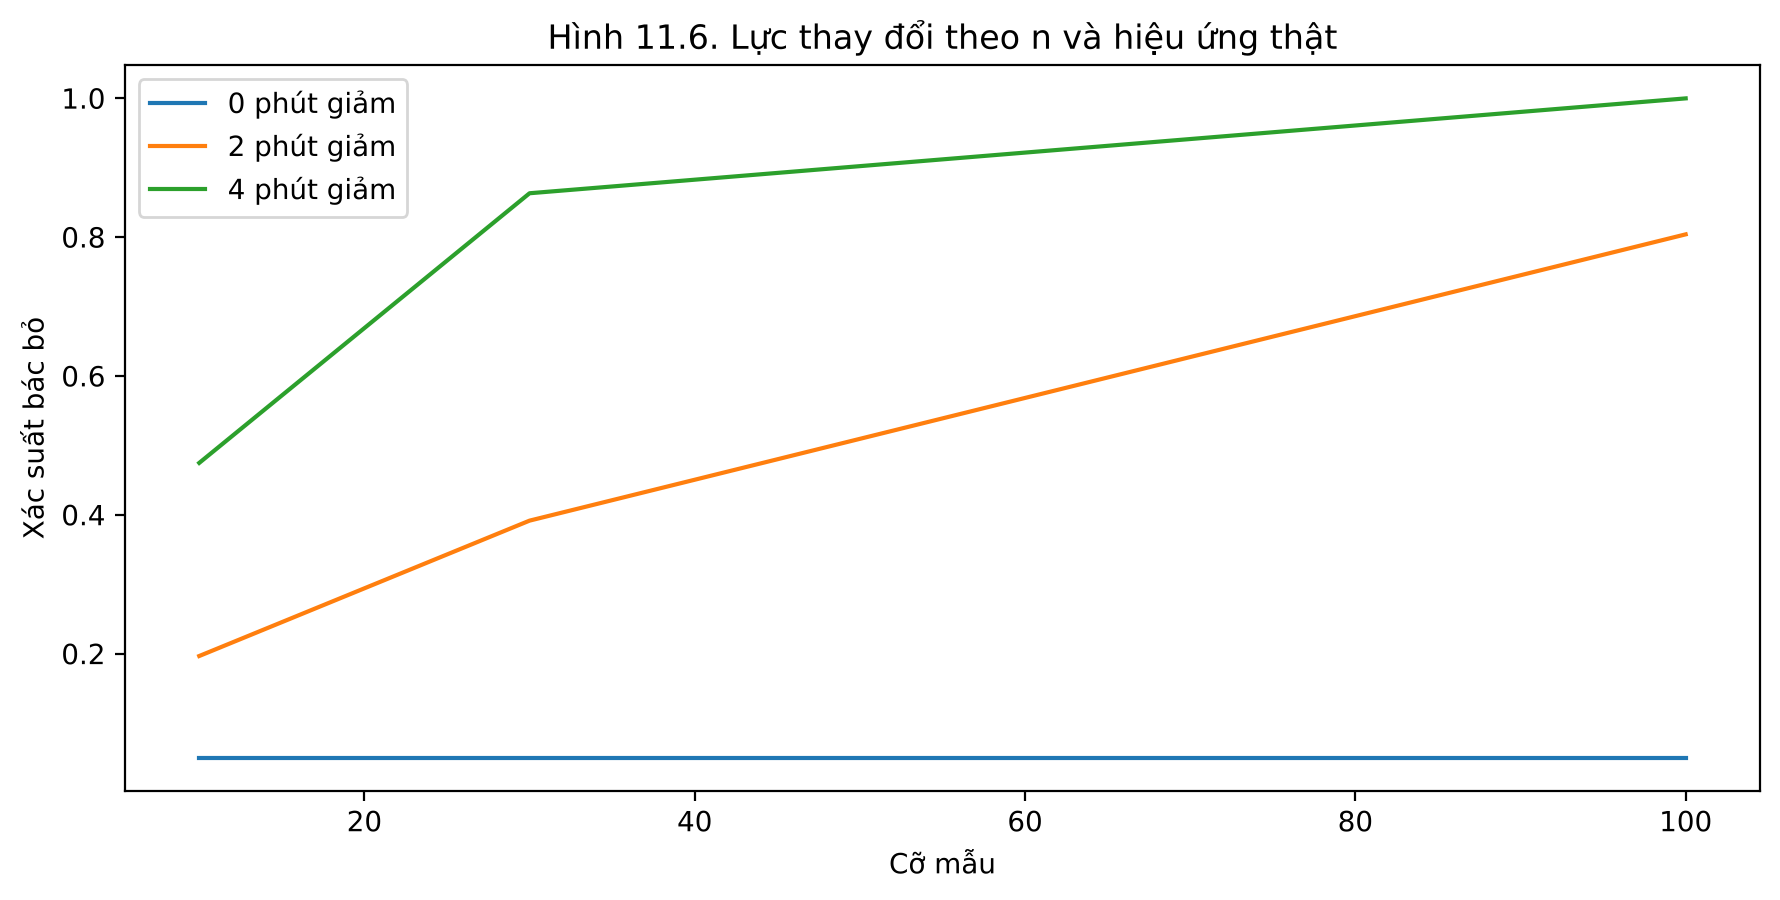

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for label, part_g in power.groupby('effect', observed=True, sort=False):
    ax.plot(part_g['n'], part_g['theory'], linewidth=1.5, label=str(label))
ax.legend()
ax.set(xlabel='Cỡ mẫu', ylabel='Xác suất bác bỏ', title='Hình 11.6. Lực thay đổi theo n và hiệu ứng thật')
fig.tight_layout()
plt.show()

**Đọc kết quả.** Hàng $\mu=75$ cho đúng 0,05 ở mọi $n$: khi $H_0$ đúng, xác suất bác bỏ là $\alpha$. Với giảm 4 phút, $n=30$ cho lực khoảng 0,86 như khối **Vì sao?** đã tính. Với giảm 2 phút, cần cỡ $n=100$ mới có lực khoảng 0,80.

**Thử đổi.** Đặt `alpha = .01` rồi chạy lại: hàng $\mu=75$ xuống 0,01, nhưng mọi giá trị lực cũng giảm. Đó là đánh đổi của Ví dụ 11.

**So sánh bội.** Với 20 kiểm định độc lập, mỗi cái ở mức 0,05, xác suất có ít nhất một báo động giả là $1-0{,}95^{20}\approx0{,}64$. Làm nhiều kiểm định rồi chỉ báo cáo cái "có ý nghĩa" vì vậy rất dễ tạo ra kết luận sai. Hiệu chỉnh Bonferroni dùng ngưỡng $0{,}05/20=0{,}0025$ cho mỗi kiểm định để giữ xác suất chung không quá 0,05; cái giá là lực của từng kiểm định giảm.

## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| Chọn kiểm định theo: loại biến, số nhóm, độc lập hay ghép cặp, tham số cần so. | Áp công thức trước khi xác định thiết kế. |
| Mọi thống kê hai trung bình: (hiệu − $\Delta_0$) / SE. | Trừ phương sai khi tính SE của hiệu (phải cộng). |
| $z$ khi biết $\sigma$; $t$ gộp khi có cơ sở cho $\sigma_1=\sigma_2$; Welch khi không. | Dùng $t$ gộp chỉ vì hai SD "trông gần nhau". |
| Ghép cặp: lấy hiệu từng cặp trước, rồi làm $t$ một mẫu với $df=n-1$. | Coi $2n$ phép đo là hai mẫu độc lập. |
| Hai tỉ lệ: SE dùng tỉ lệ gộp dưới $H_0$. | Dùng SE không gộp khi kiểm định. |
| $F$: giữ thứ tự tử–mẫu và hai bậc tự do; rất nhạy với phi chuẩn. | Dùng $F$ như bước bắt buộc trước $t$. |
| $\chi^2$: $E$ tính theo $H_0$; điều kiện $E\ge5$; bác bỏ ở đuôi phải. | Kiểm tra điều kiện trên $O$; chọn một nhóm để kiểm định sau khi nhìn bảng. |
| $df$ của $\chi^2$: $k-1$ (độ phù hợp), $(r-1)(c-1)$ (độc lập). | Dùng $k$ hoặc $rc$. |
| $\alpha$ là xác suất loại I của quy trình; lực là $1-\beta$ tại một hiệu ứng cụ thể. | Gọi giá trị p là "xác suất sai"; nói về lực mà không nêu hiệu ứng. |
| Không bác bỏ ≠ chứng minh $H_0$; bác bỏ ≠ biết nguyên nhân. | "Không khác biệt có ý nghĩa nên hai chất như nhau." |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Trước mỗi output trong bài, bạn có nói được: đơn vị là gì, tham số là gì, chiều của hiệu, $H_0$/$H_1$, điều kiện, kết luận?
2. Vì sao kiểm định $\chi^2$ luôn bác bỏ ở đuôi phải, dù $H_1$ là "khác ở đâu đó"?
3. Đo cân nặng 25 người trước và sau một chế độ ăn. Dùng kiểm định nào, bậc tự do bao nhiêu?
4. Một kiểm định có lực 30% tại mức khác biệt quan tâm. Nếu kết quả không bác bỏ $H_0$, kết quả đó có nhiều ý nghĩa không?

<details><summary>Gợi ý đáp án</summary>

1. Nếu chưa, quay lại các bước 1–2 của từng ví dụ.
2. Mỗi số hạng $(O-E)^2/E$ không âm; lệch theo hướng nào cũng làm $Q$ lớn lên. Chỉ $Q$ lớn mới là bằng chứng chống $H_0$.
3. $t$ ghép cặp trên 25 hiệu, $df=24$.
4. Không nhiều. Ngay cả khi khác biệt có thật, kiểm định này bỏ sót 70% số lần. Kết quả không bác bỏ khi đó gần như không nói gì về việc $H_0$ đúng hay sai.

</details>

**Buổi sau.** Tuần 12 chuyển sang phân tích nhân quả. Ngay cả khi hai nhóm khác nhau có ý nghĩa thống kê, cần thiết kế nào để coi khác biệt ấy là **tác động** của một can thiệp? Buổi sau học: tương quan và nhân quả, kết quả tiềm năng, biến gây nhiễu, thí nghiệm ngẫu nhiên và nghiên cứu quan sát.

## Nguồn học liệu

- Slide của học phần: `week11.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 5.5–5.6. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).